# EXP-Y8S-LM-004 — Baseline không class weighting

**Experiment ID:** `EXP-Y8S-LM-004-NO-CLASS-WEIGHT` · **Model:** `yolov8s.pt` · **Split chọn mô hình:** Validation.

### Bối cảnh
Dataset có ba lớp `anthracnose`, `leaf_miner`, `red_rust`; Leaf Miner có ít bounding box hơn Red Rust. V003 dùng `cls_pw=0.25`. V004 là run đối chứng trên cùng dataset và cùng recipe.

### Mục tiêu nghiên cứu
Đo Precision, Recall, AP50 và AP50-95 từng lớp khi **không** cân bằng classification loss, để đánh giá riêng hiệu quả của V003.

### Phương pháp
Đặt `cls_pw=0.0` nên Ultralytics không áp class weighting; trọng số hiệu dụng của cả ba lớp là 1.0. Giữ nguyên model, seed, epoch, batch, optimizer, learning rate, augmentation, AMP và cách đánh giá của V003. Không oversampling hoặc đổi split/annotation. Test không dùng để chọn mô hình.

### So sánh
Notebook báo `V003 − V004` cho từng class và mAP toàn bộ khi `metrics.json` của run còn lại có cùng model, dataset fingerprint, split và training recipe. Dấu dương cho biết V003 cao hơn ở metric đó; một seed chưa đủ chứng minh hiệu quả ổn định.

**Chạy từ đầu đến cuối.** Dataset `CASHEW_YOLO_MASTER_FINAL (2).zip` được tải theo Drive ID trong CONFIG nếu chưa có local. Khi V003 ở phiên khác, đặt `PAIR_METRICS` đến `metrics.json` trong ANALYSIS.zip của V003.


## 1. Import thư viện


In [1]:
import importlib.util, subprocess, sys
for package, module in [('ultralytics','ultralytics'),('pandas','pandas'),
                        ('matplotlib','matplotlib'),('Pillow','PIL'),('PyYAML','yaml')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install',package])
import csv, hashlib, inspect, json, os, platform, shutil, sys, time, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import yaml
import torch
import ultralytics
from ultralytics import YOLO
from ultralytics.cfg import DEFAULT_CFG_DICT
from ultralytics.models.yolo.detect.train import DetectionTrainer
from IPython.display import display

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def md5_file(path):
    digest = hashlib.md5()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


## 2. Environment & GPU Information


In [2]:
ENVIRONMENT = {'python': sys.version.split()[0], 'torch': torch.__version__,
               'ultralytics': ultralytics.__version__, 'cuda_available': torch.cuda.is_available(),
               'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
               'platform': platform.platform()}
print(json.dumps(ENVIRONMENT, ensure_ascii=False, indent=2))


{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "ultralytics": "8.4.197",
  "cuda_available": true,
  "gpu": "NVIDIA RTX PRO 6000 Blackwell Server Edition",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
}


## 3. CONFIG — chỉnh đường dẫn trước khi chạy


In [3]:
# CONFIG: mọi lựa chọn thí nghiệm tập trung tại đây.
MODEL_WEIGHTS = 'yolov8s.pt'  # hoặc 'yolo26s.pt'
MODEL_TAG = {'yolo26s.pt': 'Y26S', 'yolov8s.pt': 'Y8S'}[MODEL_WEIGHTS]
EXPERIMENT_ID = f'EXP-{MODEL_TAG}-LM-004-NO-CLASS-WEIGHT'
ARCHIVE_PREFIX = f'EXP-{MODEL_TAG}-LM-004'
DATA_ROOT = None  # thư mục dataset đã giải nén, hoặc None
DATA_ZIP = None   # ZIP đã tải sẵn; None: tìm local rồi tải từ Drive ID bên dưới
DATASET_DRIVE_FILE_ID = '1-SPLsove6H84cLf0Sr1cWByAVYdrTkbu'
DATA_SEARCH_ROOTS = [Path.cwd(), Path('/content'), Path('/kaggle/input'), Path('/kaggle/working')]
PREFERRED_ZIPS = ['CASHEW_YOLO_MASTER_FINAL (2).zip']
OUTPUT_ROOT = Path('/kaggle/working' if Path('/kaggle/working').exists() else
                   '/content' if Path('/content').exists() else Path.cwd()) / 'exp_yolo_lm_003'
NOTEBOOK_SOURCE = None  # chỉ đặt khi muốn đóng gói một file .ipynb cụ thể trên runtime
PAIR_METRICS = None  # metrics.json của V003/V004 còn lại, hoặc None để tự tìm trong OUTPUT_ROOT
OTHER_MODEL_METRICS = None  # metrics.json của model còn lại, hoặc None để tự tìm trong OUTPUT_ROOT
DRIVE_PARENT_FOLDER_ID = '1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti'
UPLOAD_TO_DRIVE = True
FINAL_TEST_EVALUATION = False
IMGSZ, EPOCHS, BATCH, SEED = 640, 80, 8, 42
OPTIMIZER, LR0, PATIENCE = 'AdamW', 0.001, 20
CLS_PW, MOSAIC, CLOSE_MOSAIC, MIXUP = 0.0, 0.4, 10, 0.0
AMP = bool(torch.cuda.is_available())
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
PRED_CONF, MATCH_IOU, LOW_CONF = 0.05, 0.50, 0.25
EXPECTED_COUNTS = {'train': 2876, 'val': 893, 'test': 412}
CLASS_NAMES = ['anthracnose', 'leaf_miner', 'red_rust']
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR = OUTPUT_ROOT / EXPERIMENT_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = {k: str(v) if isinstance(v, Path) else v for k, v in globals().copy().items()
          if k in {'MODEL_WEIGHTS','EXPERIMENT_ID','DATA_ROOT','DATA_ZIP','DATASET_DRIVE_FILE_ID','OUTPUT_ROOT',
                   'PAIR_METRICS','OTHER_MODEL_METRICS','DRIVE_PARENT_FOLDER_ID','UPLOAD_TO_DRIVE',
                   'FINAL_TEST_EVALUATION','IMGSZ','EPOCHS','BATCH','SEED','OPTIMIZER',
                   'LR0','PATIENCE','CLS_PW','MOSAIC','CLOSE_MOSAIC','MIXUP','AMP','DEVICE'}}
save_json(RUN_DIR / 'experiment_config.json', CONFIG)
print('Experiment:', EXPERIMENT_ID, '| output:', RUN_DIR)


Experiment: EXP-Y8S-LM-004-NO-CLASS-WEIGHT | output: /content/exp_yolo_lm_003/EXP-Y8S-LM-004-NO-CLASS-WEIGHT


## 4. Dataset Loading & Validation

Dataset hiện dùng: **`CASHEW_YOLO_MASTER_FINAL (2).zip`** (Google Drive file ID `1-SPLsove6H84cLf0Sr1cWByAVYdrTkbu`). Nếu chưa có ZIP local, cell sẽ tải từ Drive qua tài khoản đang xác thực. Chỉ giải nén vào thư mục output riêng; nếu gặp Train `anthracnose_1508` thì loại cặp ảnh/nhãn trong **bản sao**. Không chia lại dữ liệu. Kiểm tra ảnh Test `anthracnose_346`.


In [4]:
def safe_extract(archive, target):
    target = Path(target).resolve()
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            dest = (target / info.filename).resolve()
            if not dest.is_relative_to(target):
                raise ValueError(f'Unsafe ZIP member: {info.filename}')
        z.extractall(target)

def find_archive():
    if DATA_ZIP:
        p = Path(DATA_ZIP).expanduser()
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    for name in PREFERRED_ZIPS:
        for root in DATA_SEARCH_ROOTS:
            if root.exists():
                hits = list(root.glob(name)) + list(root.glob('*/' + name))
                if hits: return hits[0]
    destination = OUTPUT_ROOT / PREFERRED_ZIPS[0]
    if destination.is_file(): return destination
    try:
        for package,module in [('google-auth','google.auth'),
                               ('google-api-python-client','googleapiclient')]:
            try: found = importlib.util.find_spec(module)
            except ModuleNotFoundError: found = None
            if found is None: subprocess.check_call([sys.executable,'-m','pip','install',package])
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        try:
            from google.colab import auth
            auth.authenticate_user()
        except ImportError:
            pass
        credentials,_ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
        service = build('drive','v3',credentials=credentials,cache_discovery=False)
        meta = service.files().get(fileId=DATASET_DRIVE_FILE_ID,
            fields='id,name,size,md5Checksum,mimeType',supportsAllDrives=True).execute()
        if meta['name'] != PREFERRED_ZIPS[0] or not meta['name'].lower().endswith('.zip'):
            raise ValueError(f'Drive ID trỏ đến file khác: {meta}')
        request = service.files().get_media(fileId=DATASET_DRIVE_FILE_ID,supportsAllDrives=True)
        partial = destination.with_suffix('.zip.part')
        with partial.open('wb') as stream:
            downloader = MediaIoBaseDownload(stream,request,chunksize=8*1024*1024)
            done = False
            while not done:
                progress,done = downloader.next_chunk(num_retries=3)
                print('Dataset download:',f'{progress.progress():.0%}')
        if partial.stat().st_size != int(meta['size']):
            raise RuntimeError('Dataset download sai dung lượng')
        if meta.get('md5Checksum') and md5_file(partial) != meta['md5Checksum']:
            raise RuntimeError('Dataset download sai MD5')
        partial.replace(destination)
        return destination
    except Exception as exc:
        raise RuntimeError('Không tải được dataset từ Drive. Trên Colab đăng nhập Google; '
            'trên Kaggle cấp Application Default Credentials, hoặc đặt DATA_ZIP/DATA_ROOT. '
            f'Chi tiết: {type(exc).__name__}: {exc}') from exc

if DATA_ROOT:
    dataset_root = Path(DATA_ROOT).expanduser().resolve()
    source_archive = None
else:
    source_archive = find_archive()
    dataset_root = RUN_DIR / 'dataset_working_copy'
    if not dataset_root.exists() or not any(dataset_root.iterdir()):
        dataset_root.mkdir(parents=True, exist_ok=True)
        safe_extract(source_archive, dataset_root)
    print('Archive:', source_archive)

def find_split(root, split):
    aliases = ['val', 'valid', 'validation'] if split == 'val' else [split]
    candidates = []
    for alias in aliases:
        candidates += list(root.rglob(f'images/{alias}')) + list(root.rglob(f'{alias}/images'))
    candidates = [p for p in candidates if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f'Cần đúng một images/{split} hoặc {split}/images; thấy: {candidates}')
    im = candidates[0]
    lab = im.parent.parent / 'labels' / im.name if im.parent.name == 'images' else im.parent / 'labels'
    if not lab.is_dir(): raise FileNotFoundError(f'Không thấy labels cho {im}: {lab}')
    return im, lab

SPLITS = {s: find_split(dataset_root, s) for s in ('train','val','test')}
yaml_candidates = [p for p in dataset_root.rglob('*.yaml') if p.name.lower() in {'data.yaml','dataset.yaml'}]
for original_yaml in yaml_candidates:
    original = yaml.safe_load(original_yaml.read_text(encoding='utf-8')) or {}
    names = original.get('names')
    if isinstance(names, dict): names = [names.get(i, names.get(str(i))) for i in range(3)]
    if names is not None and list(names) != CLASS_NAMES:
        raise RuntimeError(f'Thứ tự class trong {original_yaml} không khớp class IDs cố định: {names}')
if source_archive:
    train_images, train_labels = SPLITS['train']
    leaked = [p for p in train_images.rglob('anthracnose_1508.*')
              if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}]
    for p in leaked:
        p.unlink()
        q = train_labels / p.relative_to(train_images).with_suffix('.txt')
        if q.exists(): q.unlink()
    print('Đã loại', len(leaked), 'ảnh Train leakage trong bản sao.')

def images_in(root):
    return sorted(p for p in root.rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'})

def label_for(image, image_dir, label_dir):
    return label_dir / image.relative_to(image_dir).with_suffix('.txt')

def read_labels(label):
    rows = []
    if not label.exists(): return rows  # ảnh âm tính hợp lệ
    for line_no, line in enumerate(label.read_text(encoding='utf-8-sig').splitlines(), 1):
        parts = line.split()
        if len(parts) != 5: raise ValueError(f'{label}:{line_no}: cần class x y w h')
        values = [float(x) for x in parts]
        cls = values[0]
        if not cls.is_integer() or int(cls) not in range(3): raise ValueError(f'{label}:{line_no}: class sai')
        x,y,w,h = values[1:]
        if not all(np.isfinite(values)) or not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            raise ValueError(f'{label}:{line_no}: box sai')
        if x-w/2 < -1e-6 or y-h/2 < -1e-6 or x+w/2 > 1+1e-6 or y+h/2 > 1+1e-6:
            raise ValueError(f'{label}:{line_no}: box vượt ảnh')
        rows.append((int(cls), x,y,w,h))
    return rows

SPLIT_IMAGES = {s: images_in(pair[0]) for s, pair in SPLITS.items()}
for s, expected in EXPECTED_COUNTS.items():
    actual = len(SPLIT_IMAGES[s])
    if actual == 0: raise RuntimeError(f'{s}: split rỗng.')
    if actual != expected:
        warnings.warn(f'{s}: {actual} ảnh, khác số dự kiến {expected}; dùng số thực tế trong báo cáo.')
for s, (im_dir, lab_dir) in SPLITS.items():
    for im in SPLIT_IMAGES[s]:
        with Image.open(im) as image: image.verify()
        read_labels(label_for(im, im_dir, lab_dir))
    orphans = [p for p in lab_dir.rglob('*.txt') if not (im_dir / p.relative_to(lab_dir).with_suffix('.jpg')).exists()
               and not any((im_dir / p.relative_to(lab_dir).with_suffix(ext)).exists() for ext in ('.jpeg','.png','.webp'))]
    if orphans: raise RuntimeError(f'{s}: orphan labels: {orphans[:5]}')
assert not any(p.stem == 'anthracnose_1508' for p in SPLIT_IMAGES['train'])
assert any(p.stem == 'anthracnose_346' for p in SPLIT_IMAGES['test'])
# Chuẩn hóa data.yaml, không chỉnh file gốc.
DATA_YAML = RUN_DIR / 'data_fixed.yaml'
data_spec = {'path': str(dataset_root.resolve()), 'train': str(SPLITS['train'][0].resolve()),
             'val': str(SPLITS['val'][0].resolve()), 'test': str(SPLITS['test'][0].resolve()),
             'nc': 3, 'names': CLASS_NAMES}
DATA_YAML.write_text(yaml.safe_dump(data_spec, allow_unicode=True, sort_keys=False), encoding='utf-8')
print('Dataset xác minh:', {s: len(v) for s,v in SPLIT_IMAGES.items()}, '| YAML:', DATA_YAML)


Archive: /content/exp_yolo_lm_003/CASHEW_YOLO_MASTER_FINAL (2).zip
Đã loại 0 ảnh Train leakage trong bản sao.
Dataset xác minh: {'train': 2876, 'val': 893, 'test': 412} | YAML: /content/exp_yolo_lm_003/EXP-Y8S-LM-004-NO-CLASS-WEIGHT/data_fixed.yaml


## 5. Dataset Statistics — số ảnh, bounding box và phân bố lớp


In [5]:
dataset_digest = hashlib.sha256()
for split, ims in SPLIT_IMAGES.items():
    im_dir, lab_dir = SPLITS[split]
    for im in ims:
        label = label_for(im, im_dir, lab_dir)
        dataset_digest.update(f'{split}/{im.relative_to(im_dir)}|{im.stat().st_size}|'.encode())
        if label.exists(): dataset_digest.update(label.read_bytes())
DATASET_STATS = {'source_archive': str(source_archive) if source_archive else None,
                 'source_md5': md5_file(source_archive) if source_archive else None,
                 'dataset_fingerprint': dataset_digest.hexdigest(), 'splits': {}}
for split, ims in SPLIT_IMAGES.items():
    im_dir, lab_dir = SPLITS[split]
    counts = Counter()
    negatives = 0
    for im in ims:
        rows = read_labels(label_for(im, im_dir, lab_dir))
        counts.update(r[0] for r in rows)
        negatives += not bool(rows)
    DATASET_STATS['splits'][split] = {'images': len(ims), 'negative_images': negatives,
                                      'boxes': {CLASS_NAMES[c]: counts[c] for c in range(3)},
                                      'total_boxes': sum(counts.values())}
save_json(RUN_DIR / 'dataset_statistics.json', DATASET_STATS)
display(pd.DataFrame(DATASET_STATS['splits']).T)
pd.DataFrame(DATASET_STATS['splits']).T.to_csv(RUN_DIR / 'dataset_statistics.csv')


,images,negative_images,boxes,total_boxes
train,2876,0,"{'anthracnose': 34887, 'leaf_miner': 2076, 're...",110035
val,893,0,"{'anthracnose': 14507, 'leaf_miner': 568, 'red...",47258
test,412,0,"{'anthracnose': 2907, 'leaf_miner': 372, 'red_...",17670


## 6. Class Weight Calculation & Verification

Tính từ **box Train**, không tính từ số ảnh; lớp vắng box là lỗi dataset. Kiểm tra API công khai và logic trainer trước khi train.


In [6]:
train_counts = np.array([DATASET_STATS['splits']['train']['boxes'][n] for n in CLASS_NAMES], dtype=float)
if np.any(train_counts <= 0): raise RuntimeError('Có lớp không có box Train.')
raw_weights = (1.0 / train_counts) ** CLS_PW
expected_weights = raw_weights / raw_weights.mean()
CLASS_WEIGHTS = {'cls_pw': CLS_PW, 'train_box_counts': dict(zip(CLASS_NAMES, train_counts.astype(int).tolist())),
                 'expected_normalized': dict(zip(CLASS_NAMES, expected_weights.tolist()))}
if 'cls_pw' not in DEFAULT_CFG_DICT or not hasattr(DetectionTrainer, 'set_class_weights'):
    raise RuntimeError(f'Ultralytics {ultralytics.__version__} thiếu cls_pw/set_class_weights. Cập nhật Ultralytics để hai run dùng cùng API.')
trainer_source = inspect.getsource(DetectionTrainer.set_class_weights)
if 'compute_class_weights' not in trainer_source or not hasattr(DetectionTrainer, 'compute_class_weights'):
    raise RuntimeError('Trainer không dùng class weights như mong đợi; kiểm tra phiên bản Ultralytics.')
save_json(RUN_DIR / 'class_weights.json', CLASS_WEIGHTS)
display(pd.DataFrame({'class': CLASS_NAMES, 'train_boxes': train_counts.astype(int), 'weight_expected': expected_weights}))


,class,train_boxes,weight_expected
0,anthracnose,34887,1.0
1,leaf_miner,2076,1.0
2,red_rust,73072,1.0


## 7. Augmentation Configuration


In [7]:
AUGMENTATION = {'mosaic': MOSAIC, 'close_mosaic': CLOSE_MOSAIC, 'mixup': MIXUP}
save_json(RUN_DIR / 'augmentation_config.json', AUGMENTATION)
print(AUGMENTATION)


{'mosaic': 0.4, 'close_mosaic': 10, 'mixup': 0.0}


## 8. Model Initialization


In [8]:
model = YOLO(MODEL_WEIGHTS)
print(model.model)
PARAMETERS = sum(p.numel() for p in model.model.parameters())
print('Parameters:', PARAMETERS, '| device:', DEVICE)
ENVIRONMENT['parameters'] = PARAMETERS
save_json(RUN_DIR / 'environment.json', ENVIRONMENT)


DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
    

## 9. Training — Validation dùng cho early stopping; Test giữ độc lập


In [9]:
train_kwargs = dict(data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH,
                    seed=SEED, optimizer=OPTIMIZER, lr0=LR0, patience=PATIENCE,
                    cls_pw=CLS_PW, mosaic=MOSAIC, close_mosaic=CLOSE_MOSAIC,
                    mixup=MIXUP, amp=AMP, device=DEVICE, project=str(RUN_DIR),
                    name='train', exist_ok=True, plots=True, val=True, save=True)
t0 = time.perf_counter()
train_result = model.train(**train_kwargs)
TRAIN_SECONDS = time.perf_counter() - t0
TRAIN_RUN = RUN_DIR / 'train'
BEST_PT, LAST_PT = TRAIN_RUN / 'weights/best.pt', TRAIN_RUN / 'weights/last.pt'
if not BEST_PT.is_file() or not LAST_PT.is_file(): raise FileNotFoundError('Thiếu best.pt/last.pt')
trainer = model.trainer
actual_tensor = getattr(trainer.model, 'class_weights', None)
if CLS_PW > 0 and actual_tensor is None:
    raise RuntimeError('Trainer không ghi class_weights; không chấp nhận run weighting này.')
actual_weights = (actual_tensor.detach().cpu().numpy().reshape(-1)
                  if actual_tensor is not None else np.ones(3, dtype=float))
if len(actual_weights) != 3 or not np.allclose(actual_weights, expected_weights, rtol=1e-4, atol=1e-4):
    raise RuntimeError(f'Trọng số trainer {actual_weights} khác dự kiến {expected_weights}')
CLASS_WEIGHTS['actual_trainer'] = (dict(zip(CLASS_NAMES, actual_weights.tolist()))
                                   if actual_tensor is not None else None)
CLASS_WEIGHTS['effective'] = dict(zip(CLASS_NAMES, actual_weights.tolist()))
CLASS_WEIGHTS['weighting_enabled'] = bool(CLS_PW > 0)
CLASS_WEIGHTS['verified'] = True
save_json(RUN_DIR / 'class_weights.json', CLASS_WEIGHTS)
print(f'Train: {TRAIN_SECONDS:.1f}s; effective weights:', CLASS_WEIGHTS['effective'])


Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/exp_yolo_lm_003/EXP-Y8S-LM-004-NO-CLASS-WEIGHT/data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.4, mult

## 10. Save Checkpoints & Training History


In [10]:
HISTORY_CSV = TRAIN_RUN / 'results.csv'
if not HISTORY_CSV.is_file(): raise FileNotFoundError(HISTORY_CSV)
history = pd.read_csv(HISTORY_CSV)
history.columns = history.columns.str.strip()
history.to_csv(RUN_DIR / 'results.csv', index=False)
save_json(RUN_DIR / 'training_summary.json', {'training_seconds': TRAIN_SECONDS,
    'best_checkpoint': str(BEST_PT), 'last_checkpoint': str(LAST_PT),
    'completed_epochs': len(history), 'best_checkpoint_md5': md5_file(BEST_PT)})
display(history.tail())


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
56,57,517.711,1.70434,1.07323,0.99530,0.68242,0.65534,0.69873,0.37086,1.71675,1.13594,0.97315,0.000307,0.000307,0.000307
57,58,526.553,1.70415,1.07381,0.99473,0.67037,0.65055,0.69383,0.37216,1.71699,1.14843,0.97623,0.000295,0.000295,0.000295
58,59,535.599,1.69694,1.07104,0.99375,0.67767,0.65777,0.69618,0.35617,1.77770,1.16670,0.98304,0.000282,0.000282,0.000282
59,60,544.417,1.69429,1.06631,0.98926,0.68279,0.66121,0.70230,0.37600,1.72099,1.14009,0.98012,0.000270,0.000270,0.000270
60,61,553.470,1.69917,1.05850,0.99016,0.69136,0.64639,0.69433,0.36921,1.72338,1.14984,0.97697,0.000258,0.000258,0.000258


## 11. Validation Evaluation


In [11]:
best_model = YOLO(str(BEST_PT))
val_metrics = best_model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH,
                             device=DEVICE, plots=True, project=str(RUN_DIR), name='validation', exist_ok=True)
VALIDATION_RUN = RUN_DIR / 'validation'
METRICS = {'experiment_id': EXPERIMENT_ID, 'model': MODEL_WEIGHTS, 'split': 'val',
           'dataset_source_md5': DATASET_STATS['source_md5'],
           'dataset_fingerprint': DATASET_STATS['dataset_fingerprint'], 'cls_pw': CLS_PW,
           'ultralytics_version': ultralytics.__version__, 'torch_version': torch.__version__,
           'training_seconds': TRAIN_SECONDS,
           'training_recipe': {k:CONFIG[k] for k in ('IMGSZ','EPOCHS','BATCH','SEED','OPTIMIZER',
               'LR0','PATIENCE','MOSAIC','CLOSE_MOSAIC','MIXUP','AMP')},
           'map50': float(val_metrics.box.map50),
           'map50_95': float(val_metrics.box.map),
           'speed_ms_per_image': {k: float(v) for k,v in val_metrics.speed.items()}}
print(json.dumps(METRICS, indent=2))


Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3836.4±1336.0 MB/s, size: 48.4 KB)
val: Scanning /content/exp_yolo_lm_003/EXP-Y8S-LM-004-NO-CLASS-WEIGHT/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL/labels/val.cache... 893 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 893/893 468.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 112/112 19.5it/s 5.7s0.1s
                   all        893      47258      0.701      0.662      0.709      0.383
           anthracnose        752      14507      0.688       0.57      0.642      0.302
            leaf_miner        270        568      0.743      0.717      0.764      0.509
              red_rust        455      32183      0.671        0.7       0.72      0.337
Speed: 

## 12. Per-Class Metrics và macro average


In [12]:
rows = []
for cls_id, name in enumerate(CLASS_NAMES):
    if cls_id not in val_metrics.box.ap_class_index:
        raise RuntimeError(f'Validation không có GT cho {name}; không thể báo metric per-class.')
    metric_index = list(val_metrics.box.ap_class_index).index(cls_id)
    p, r, ap50, ap = val_metrics.box.class_result(metric_index)
    rows.append({'class_id': cls_id, 'class': name, 'precision': float(p), 'recall': float(r),
                 'ap50': float(ap50), 'ap50_95': float(ap),
                 'train_boxes': int(train_counts[cls_id]), 'class_weight': float(actual_weights[cls_id])})
per_class = pd.DataFrame(rows)
per_class.to_csv(RUN_DIR / 'per_class_metrics.csv', index=False)
METRICS['per_class'] = rows
METRICS['macro'] = {k: float(per_class[k].mean()) for k in ('precision','recall','ap50','ap50_95')}
save_json(RUN_DIR / 'metrics.json', METRICS)
display(per_class)


,class_id,class,precision,recall,ap50,ap50_95,train_boxes,class_weight
0,0,anthracnose,0.687777,0.569879,0.642069,0.302301,34887,1.0
1,1,leaf_miner,0.743376,0.716549,0.763914,0.508914,2076,1.0
2,2,red_rust,0.670750,0.700214,0.720312,0.336926,73072,1.0


## 13. Learning Curves — train/val losses theo epoch


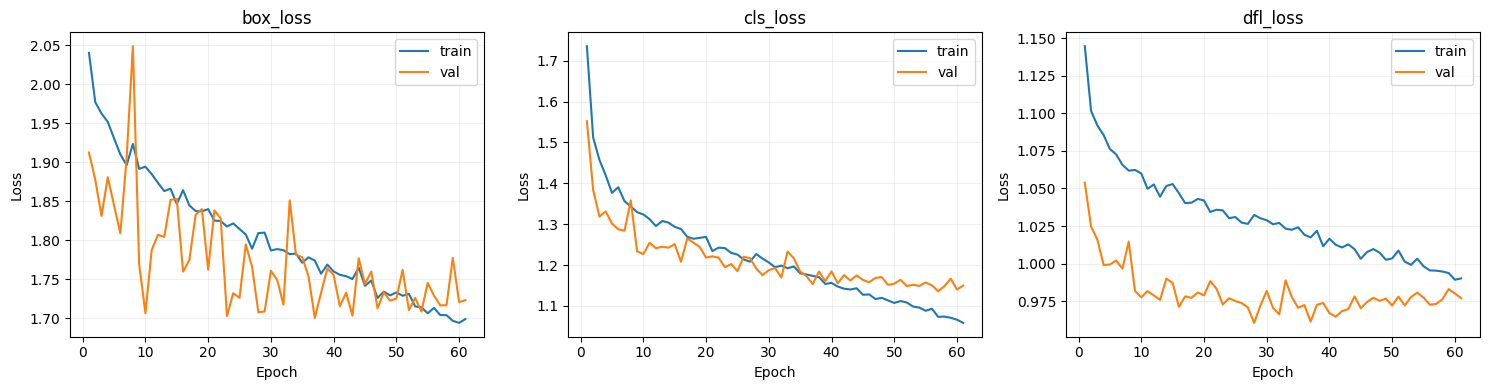

In [13]:
distance_loss = 'l1_loss' if 'train/l1_loss' in history.columns else 'dfl_loss'
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, component in zip(axes, ('box_loss','cls_loss',distance_loss)):
    for prefix in ('train','val'):
        key = f'{prefix}/{component}'
        if key in history: ax.plot(history['epoch'], history[key], label=prefix)
    ax.set(title=component, xlabel='Epoch', ylabel='Loss'); ax.grid(alpha=.2)
    if ax.lines: ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160); plt.show()


## 14. Precision–Recall Curves


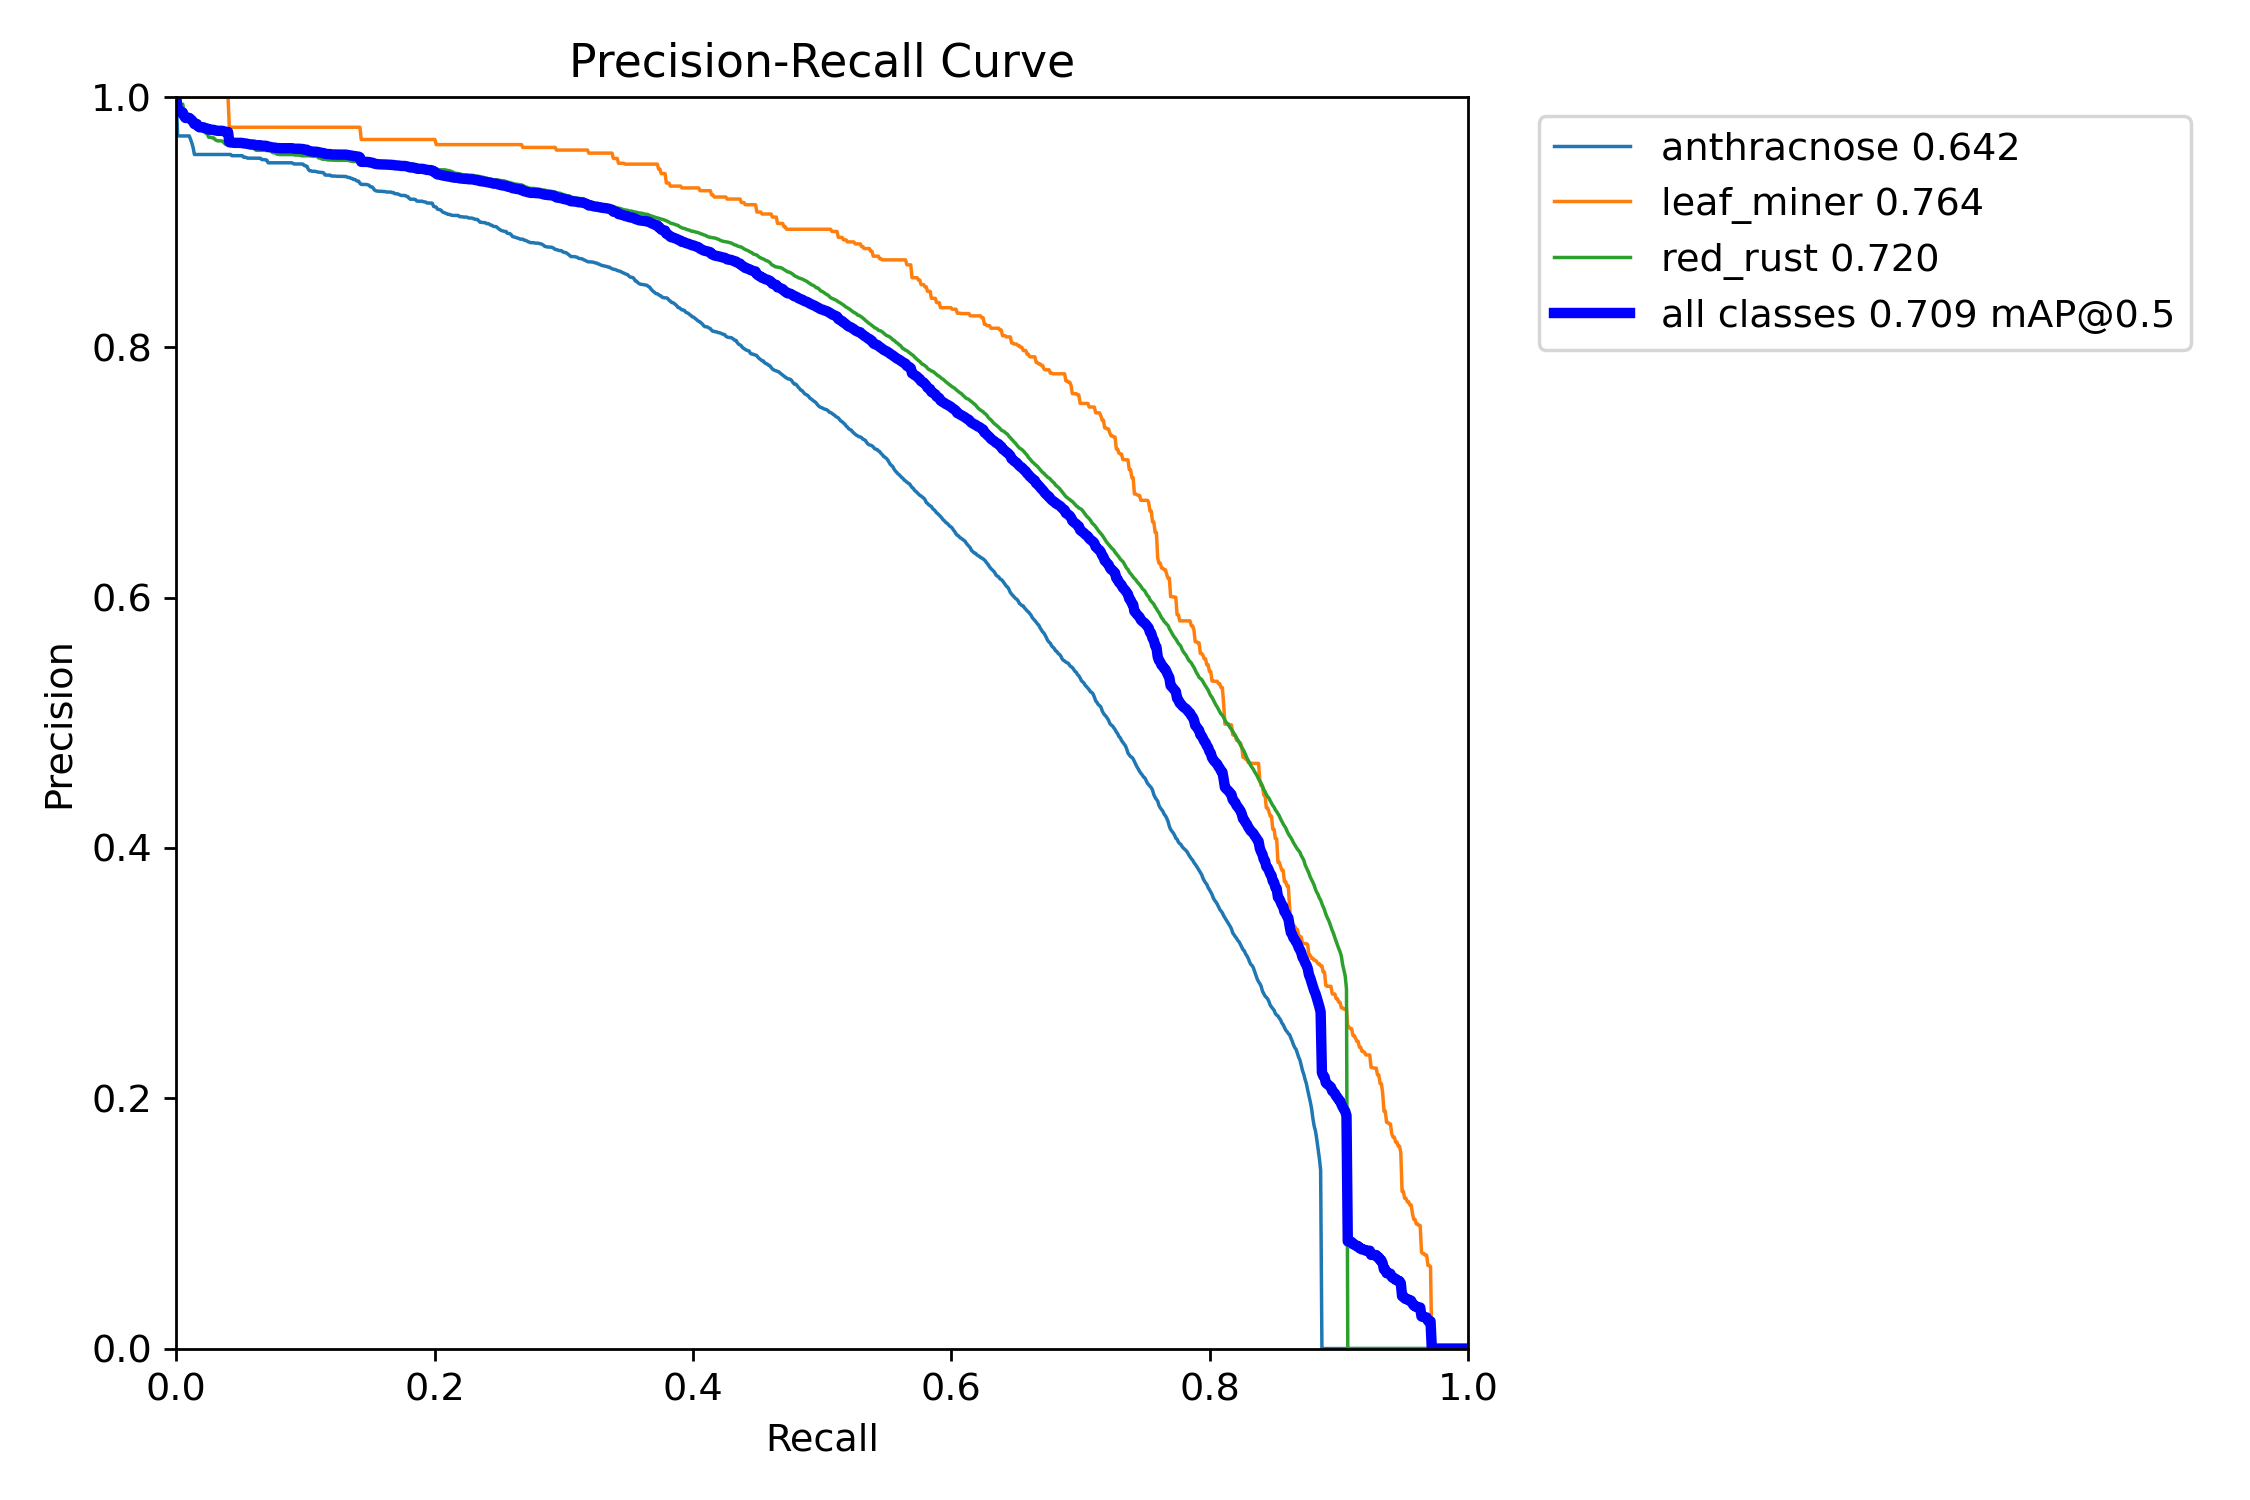

In [14]:
def require_plot(name):
    p = VALIDATION_RUN / name
    if not p.is_file(): raise FileNotFoundError(f'Thiếu plot Ultralytics: {p}')
    display(Image.open(p))
    shutil.copy2(p, RUN_DIR / name)
require_plot('BoxPR_curve.png')


## 15. F1–Confidence, Precision–Confidence, Recall–Confidence


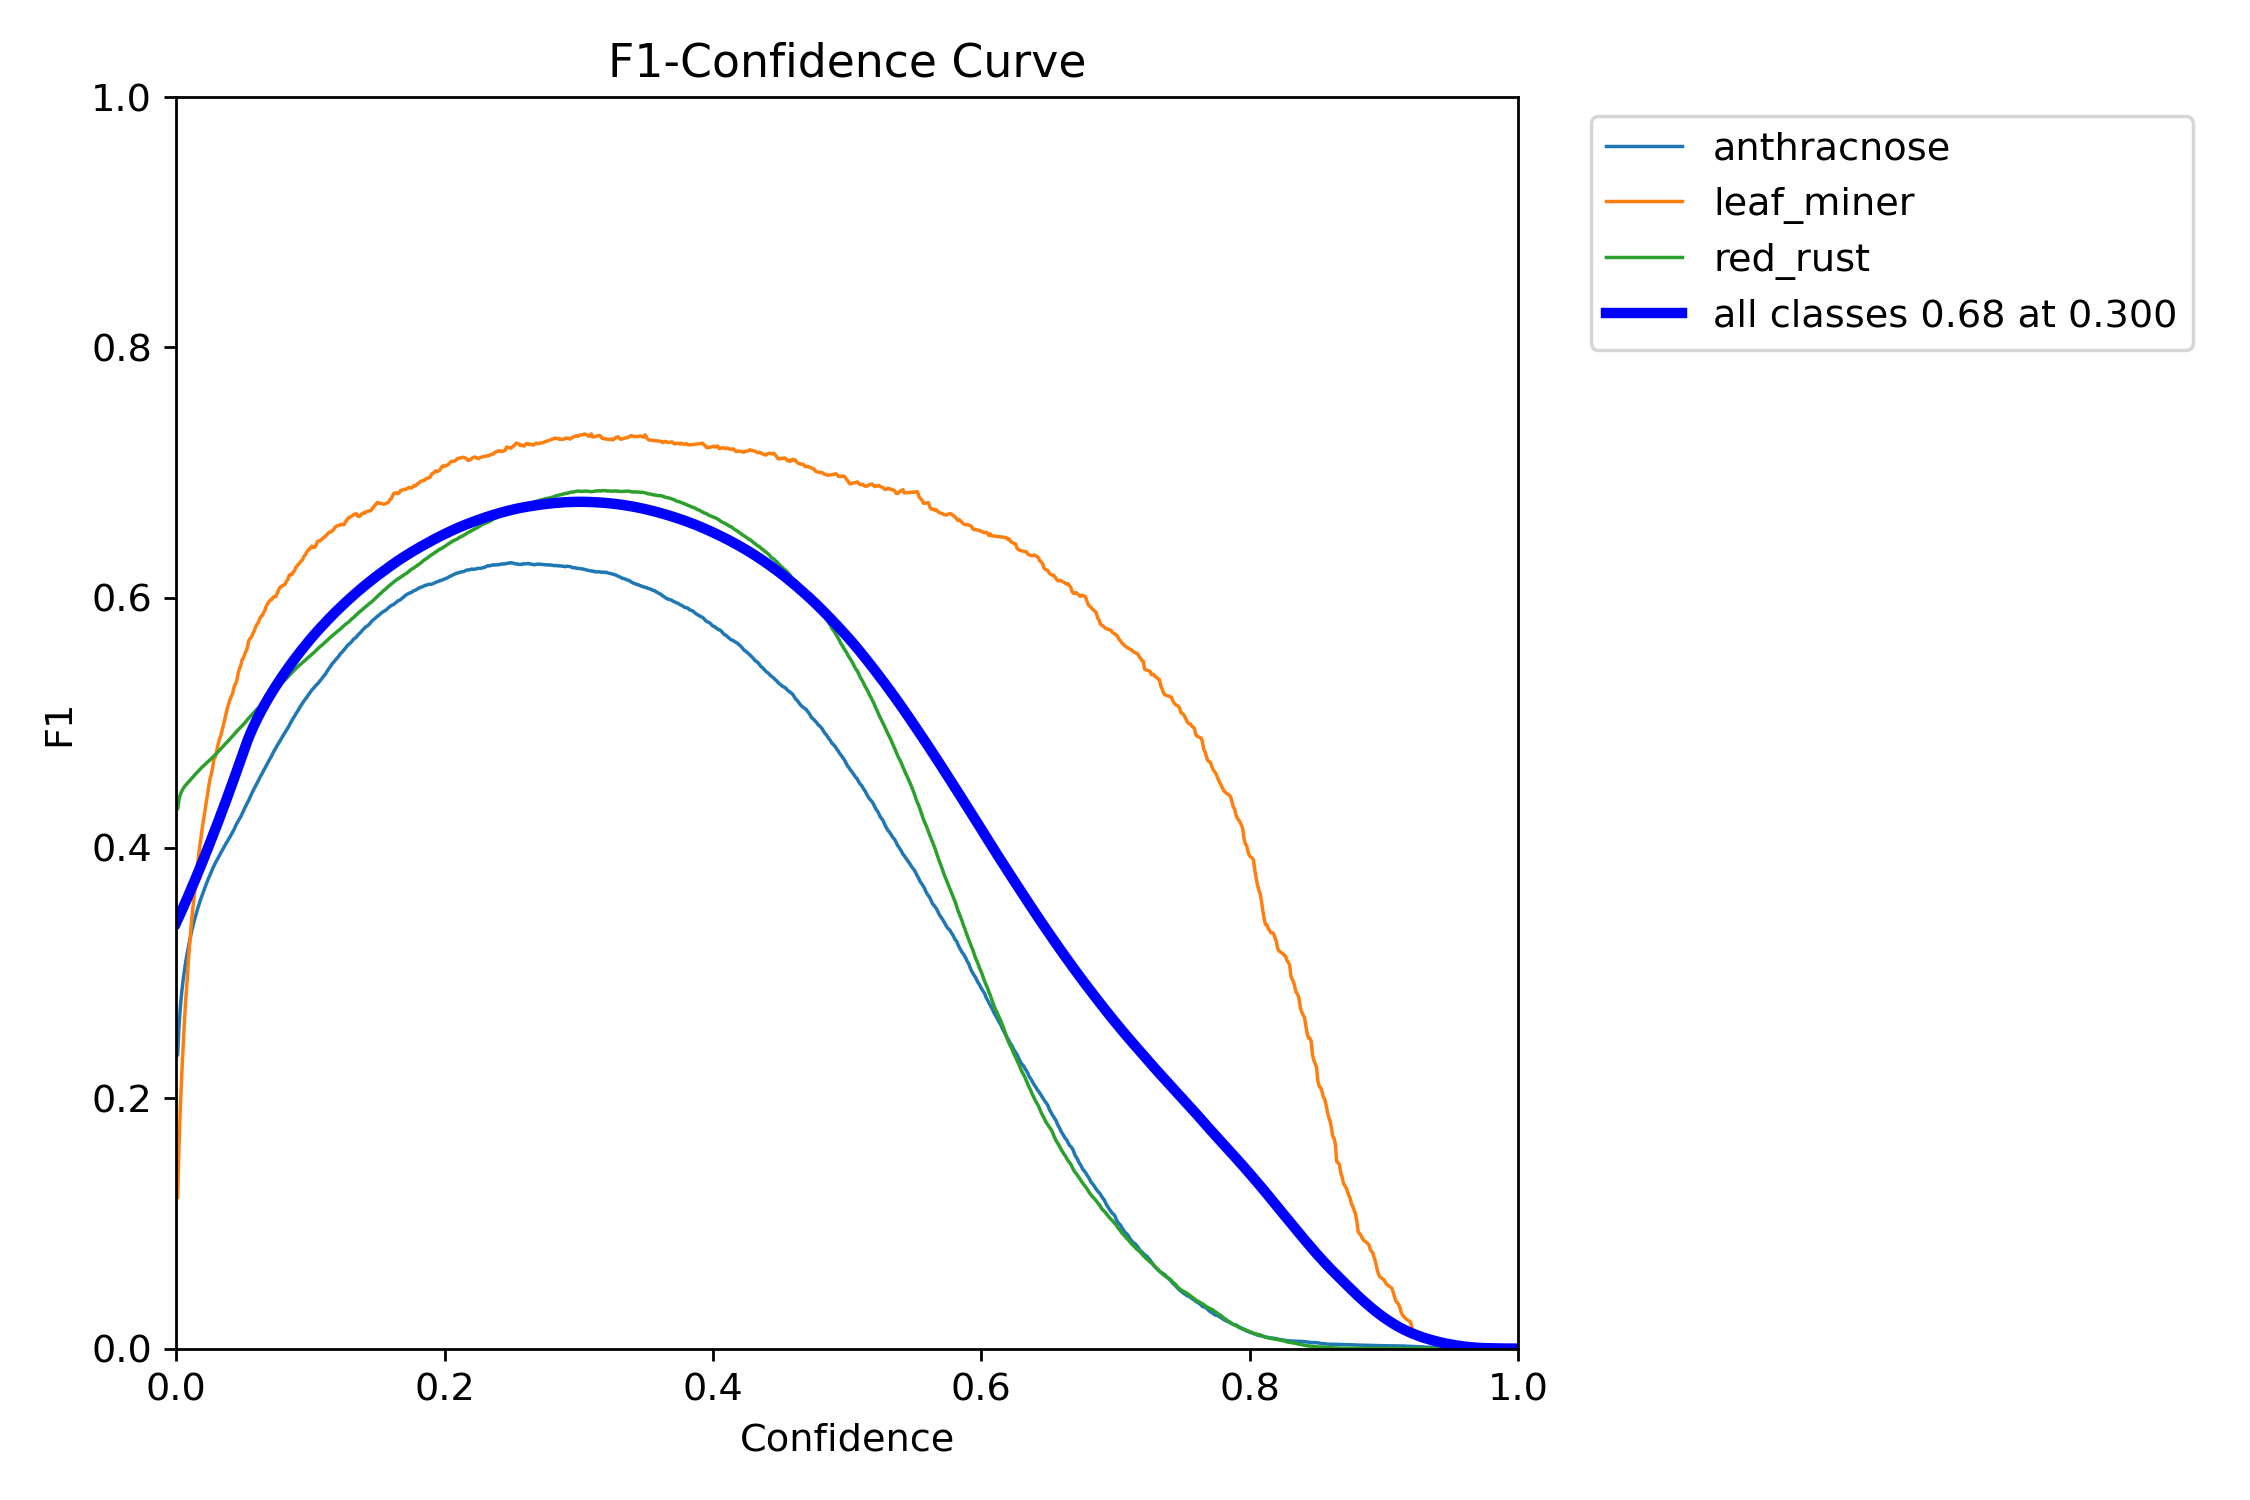

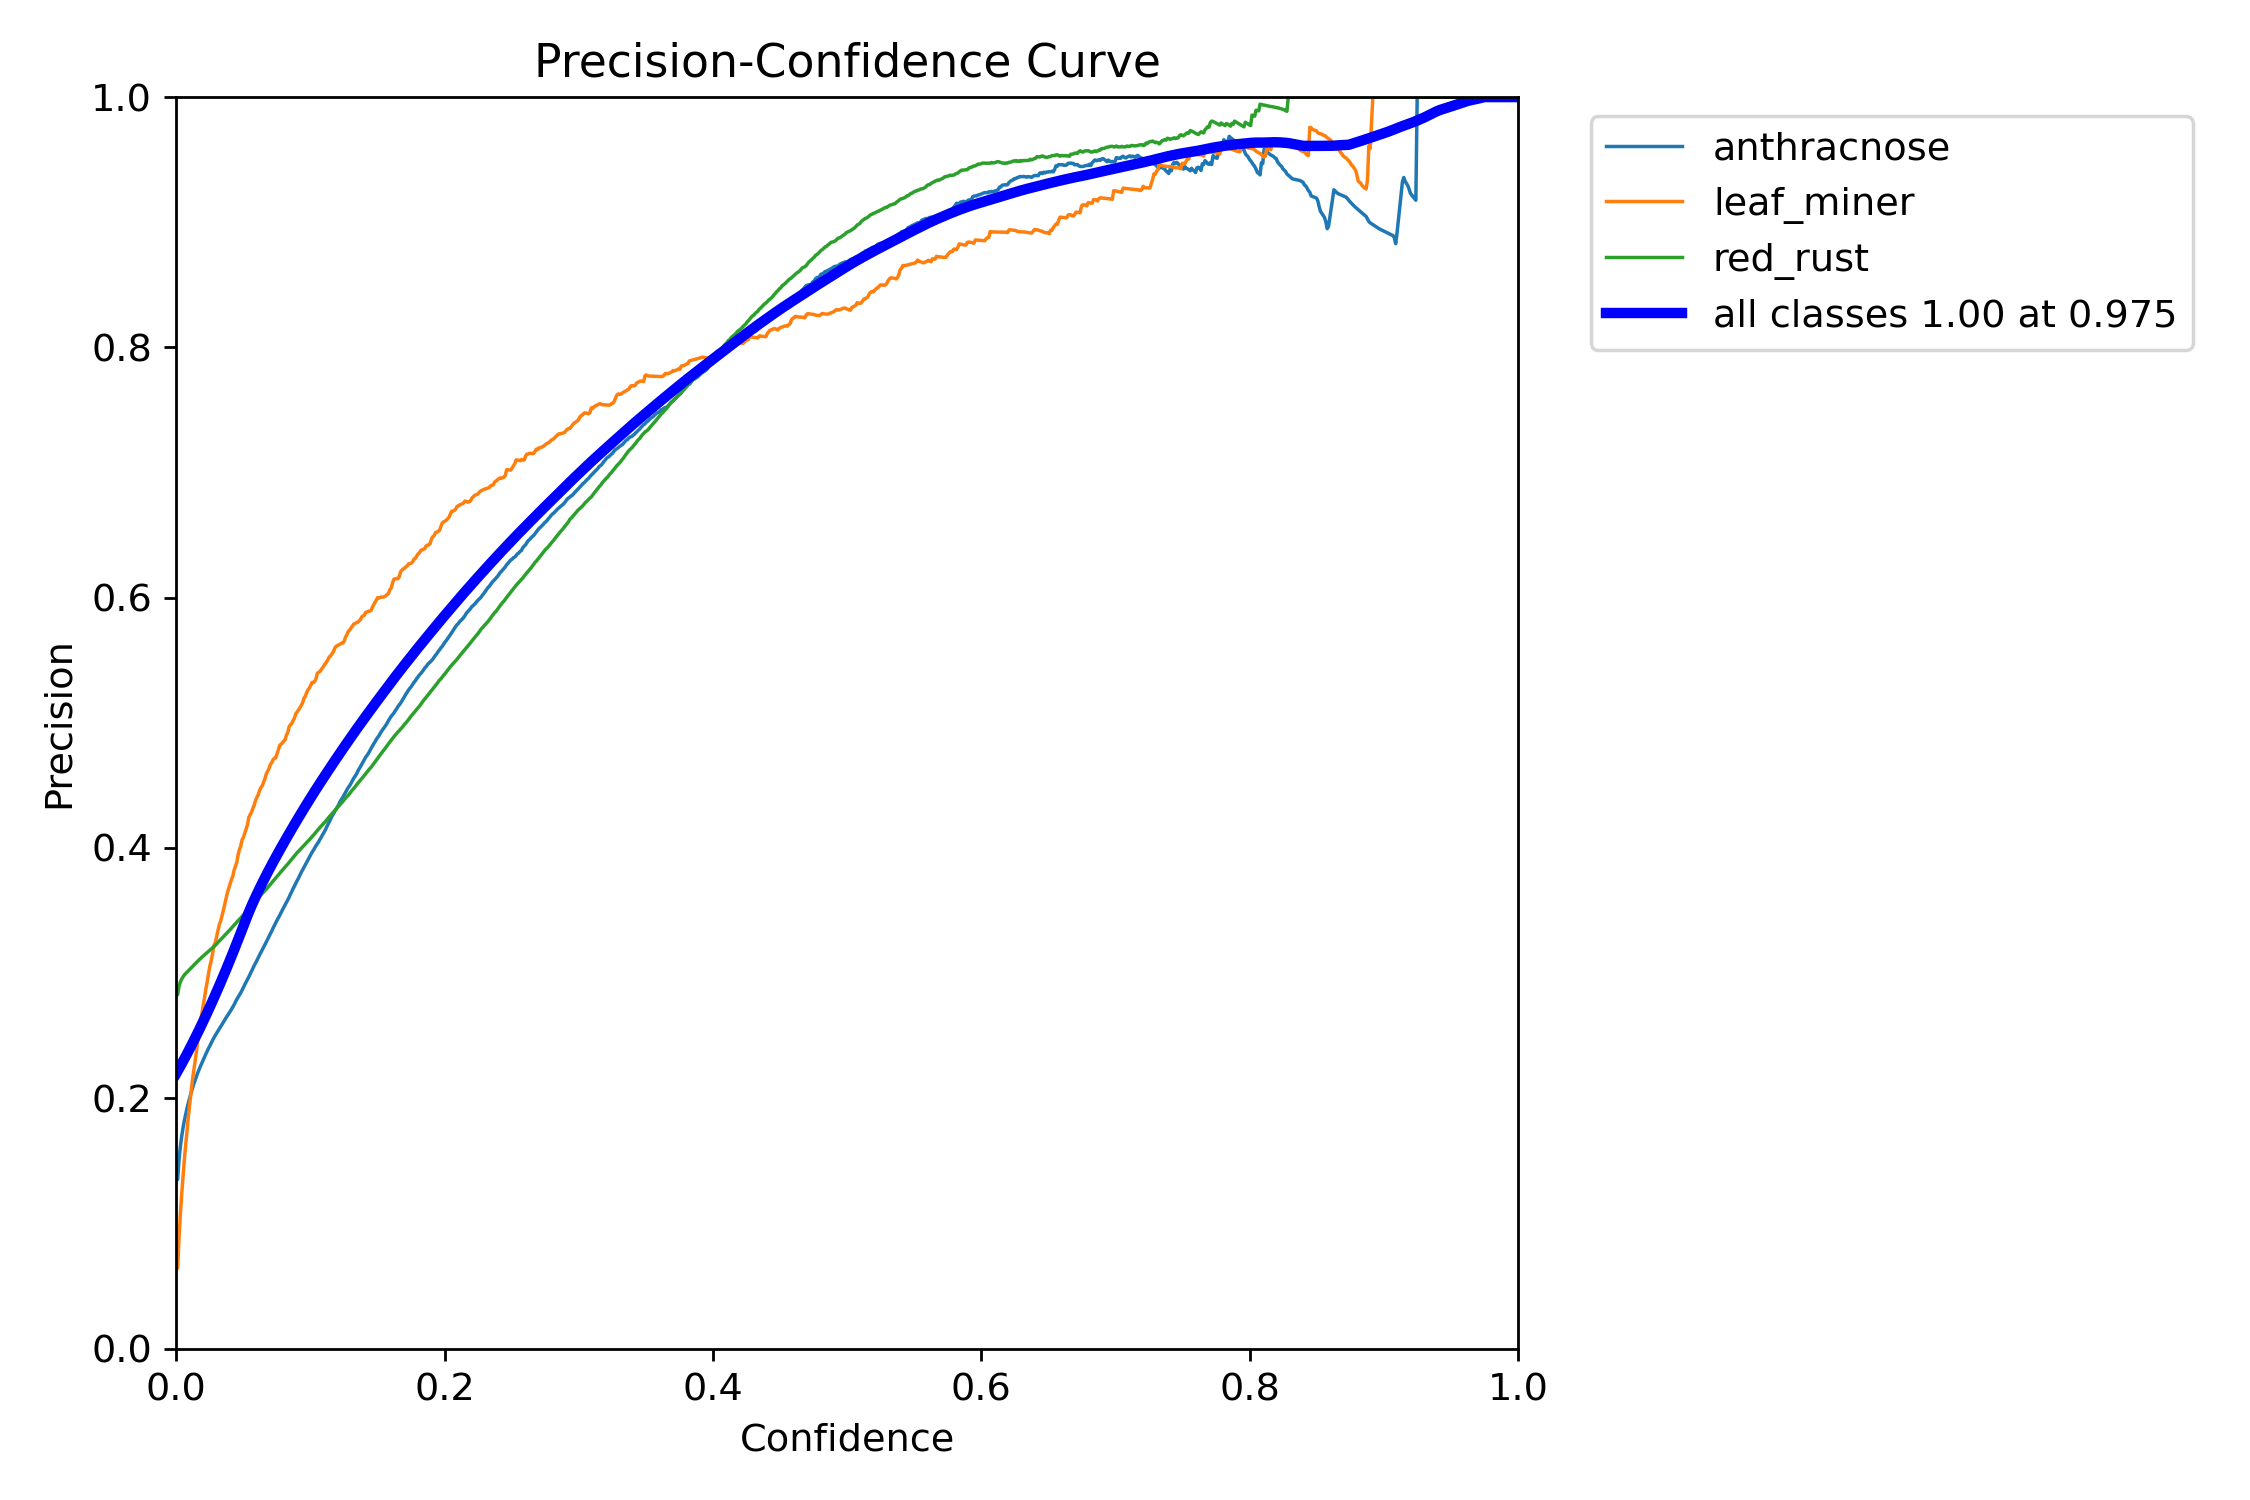

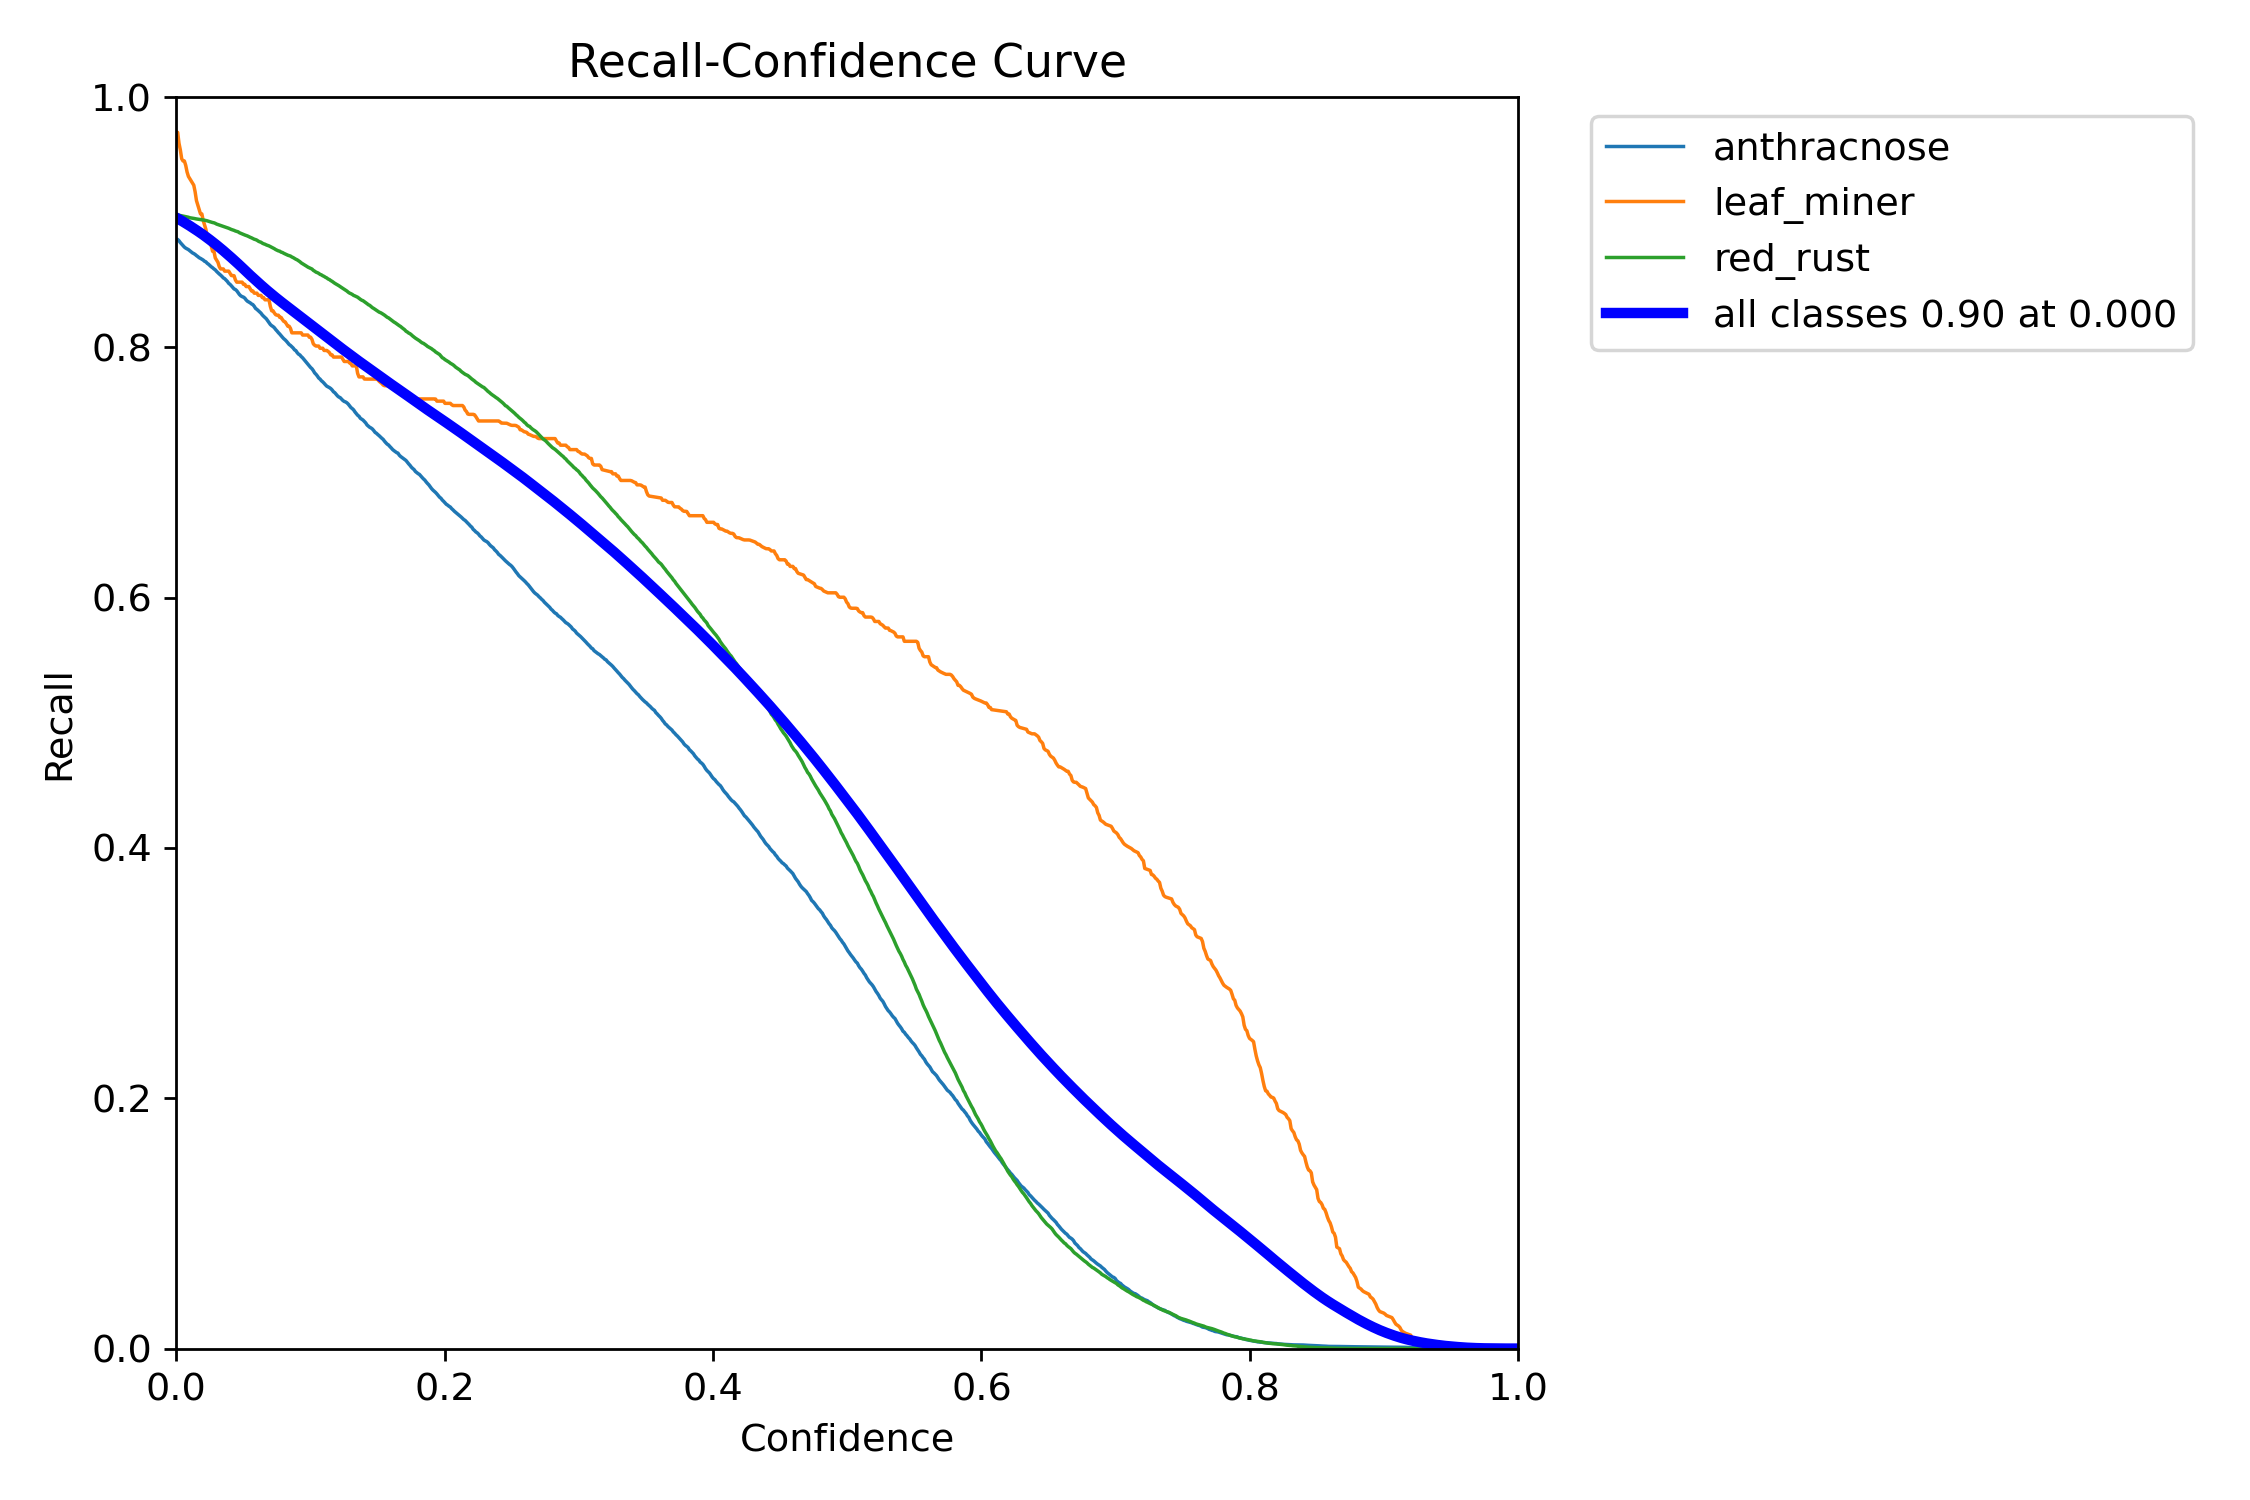

In [15]:
for plot_name in ('BoxF1_curve.png','BoxP_curve.png','BoxR_curve.png'):
    require_plot(plot_name)


## 16. Confusion Matrix


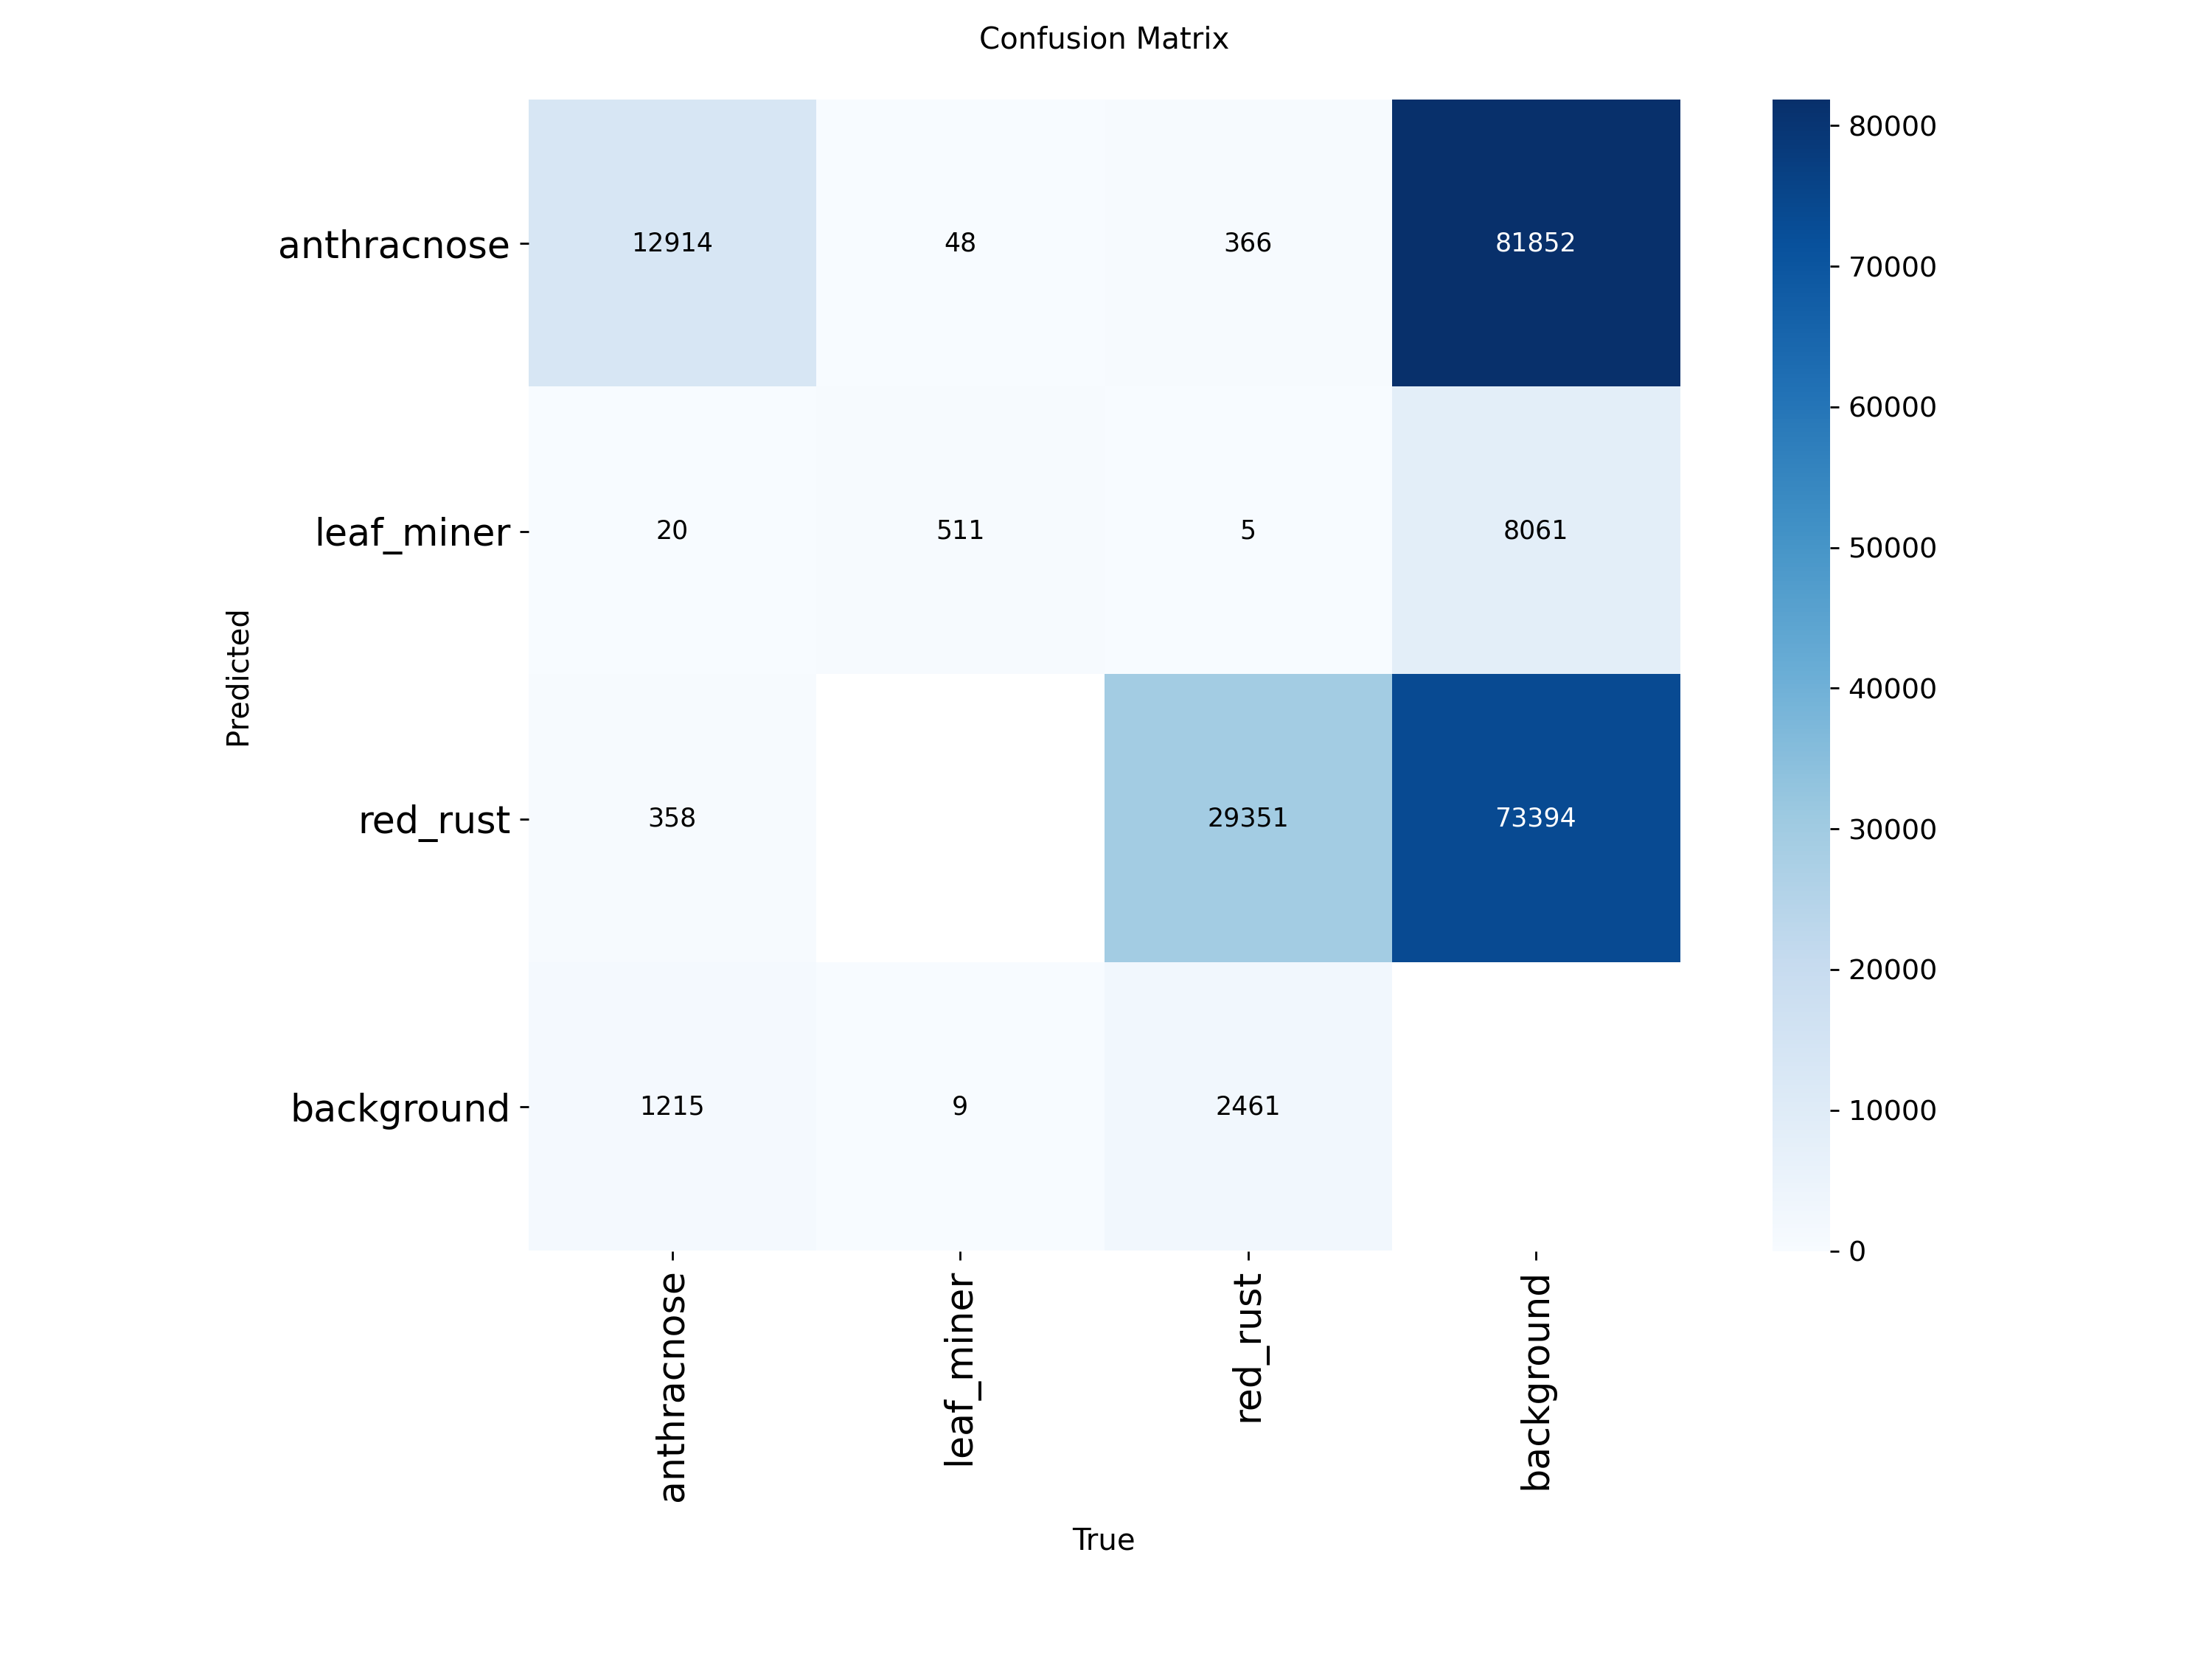

[[      12914          48         366       81852]
 [         20         511           5        8061]
 [        358           0       29351       73394]
 [       1215           9        2461           0]]


In [16]:
require_plot('confusion_matrix.png')
cm = getattr(getattr(val_metrics,'confusion_matrix',None), 'matrix', None)
if cm is not None:
    np.savetxt(RUN_DIR / 'confusion_matrix.csv', cm, delimiter=',', fmt='%d')
    print(cm)


## 17. Leaf Miner Failure Analysis

Ghép dự đoán với ground truth theo class và IoU ≥ 0.5, theo confidence giảm dần. Dự đoán Leaf Miner không ghép là FP; ground truth Leaf Miner không ghép là FN. `0.1 ≤ IoU < 0.5` là gợi ý box lệch, không cộng là TP. Lưu 20 ảnh Validation ưu tiên lỗi và trường hợp nhiều bệnh.


In [17]:
def xywhn_to_xyxy(row, width, height):
    _, x,y,w,h = row
    return np.array([(x-w/2)*width,(y-h/2)*height,(x+w/2)*width,(y+h/2)*height], dtype=float)

def iou(a,b):
    x1,y1 = np.maximum(a[:2], b[:2]); x2,y2 = np.minimum(a[2:], b[2:])
    intersection = max(0,x2-x1)*max(0,y2-y1)
    aa = max(0,a[2]-a[0])*max(0,a[3]-a[1]); bb = max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return intersection/(aa+bb-intersection+1e-9)

def draw_example(src, gt, pred, destination):
    img = Image.open(src).convert('RGB')
    draw = ImageDraw.Draw(img)
    colors = ['#d77b27','#d62d32','#1f78b4']
    for c,box in gt:
        draw.rectangle(tuple(box), outline=colors[c], width=3)
        draw.text(tuple(box[:2]), 'GT '+CLASS_NAMES[c], fill=colors[c])
    for c,conf,box in pred:
        draw.rectangle(tuple(box), outline='#00cc66', width=2)
        draw.text(tuple(box[:2]), f'P {CLASS_NAMES[c]} {conf:.2f}', fill='#00aa55')
    img.save(destination)

failure_rows, samples = [], []
PREDICTIONS_DIR = RUN_DIR / 'validation_predictions'; PREDICTIONS_DIR.mkdir(exist_ok=True)
im_dir, lab_dir = SPLITS['val']
for idx, im in enumerate(SPLIT_IMAGES['val']):
    gt_labels = read_labels(label_for(im, im_dir, lab_dir))
    with Image.open(im) as source: width,height = source.size
    gt = [(r[0], xywhn_to_xyxy(r,width,height)) for r in gt_labels]
    prediction = best_model.predict(source=str(im), imgsz=IMGSZ, conf=PRED_CONF,
                                    device=DEVICE, verbose=False)[0]
    pred = [(int(c),float(score),box) for c,score,box in zip(
        prediction.boxes.cls.cpu().numpy(), prediction.boxes.conf.cpu().numpy(),
        prediction.boxes.xyxy.cpu().numpy())]
    pred.sort(key=lambda x: -x[1]); matched = set(); fp=fn=shifted=low=tp=0
    for c,score,box in pred:
        if c != 1: continue
        eligible = [(j,iou(box,gbox)) for j,(gc,gbox) in enumerate(gt) if gc==1 and j not in matched]
        best_j,best_iou = max(eligible,key=lambda z:z[1]) if eligible else (None,0.)
        if best_iou >= MATCH_IOU:
            matched.add(best_j); tp += 1; low += score < LOW_CONF
        else:
            fp += 1; shifted += 0.1 <= best_iou < MATCH_IOU
    fn = sum(c==1 and j not in matched for j,(c,_) in enumerate(gt))
    multi = len(set(c for c,_ in gt)) > 1
    row = {'image':str(im.relative_to(im_dir)), 'leaf_miner_tp':tp,'leaf_miner_fp':fp,
           'leaf_miner_fn':fn,'shifted_boxes_candidate':shifted,'low_confidence_tp':low,
           'multi_disease_gt':bool(multi)}
    failure_rows.append(row)
    score = 10*(fp+fn)+5*shifted+3*low+2*multi
    samples.append((score, idx, im, gt, pred))
    if (idx+1)%100==0: print('Analysed',idx+1,'/',len(SPLIT_IMAGES['val']))
failures = pd.DataFrame(failure_rows)
failures.to_csv(RUN_DIR / 'leaf_miner_failure_analysis.csv',index=False)
error_samples = sorted((s for s in samples if s[0]>0),key=lambda z:(-z[0],z[1]))[:15]
correct_samples = [s for s in samples if s[0]==0][:5]
chosen = error_samples + correct_samples
if len(chosen)<20:
    used = {s[1] for s in chosen}
    chosen += [s for s in samples if s[1] not in used][:20-len(chosen)]
for _,idx,im,gt,pred in chosen:
    draw_example(im,gt,pred,PREDICTIONS_DIR / f'{idx:04d}_{im.stem}.jpg')
FAILURE_SUMMARY = {k:int(failures[k].sum()) for k in
                   ('leaf_miner_tp','leaf_miner_fp','leaf_miner_fn','shifted_boxes_candidate',
                    'low_confidence_tp','multi_disease_gt')}
save_json(RUN_DIR / 'leaf_miner_failure_summary.json',FAILURE_SUMMARY)
print(FAILURE_SUMMARY)


Analysed 100 / 893
Analysed 200 / 893
Analysed 300 / 893
Analysed 400 / 893
Analysed 500 / 893
Analysed 600 / 893
Analysed 700 / 893
Analysed 800 / 893
{'leaf_miner_tp': 475, 'leaf_miner_fp': 678, 'leaf_miner_fn': 93, 'shifted_boxes_candidate': 110, 'low_confidence_tp': 62, 'multi_disease_gt': 503}


## 18. Experiment Summary & So sánh V003–V004

Chỉ so sánh khi cùng model, dataset fingerprint, Validation, seed và training recipe. Dấu Δ luôn là **V003 có weighting trừ V004 không weighting**. Nếu run còn lại ở phiên khác, đặt `PAIR_METRICS` đến `metrics.json` hoặc trực tiếp đến ANALYSIS.zip đã tải về.


In [18]:
pair_id = (f'EXP-{MODEL_TAG}-LM-004-NO-CLASS-WEIGHT' if CLS_PW > 0 else
           f'EXP-{MODEL_TAG}-LM-003-CLASS-WEIGHTED')
pair_path = Path(PAIR_METRICS) if PAIR_METRICS else OUTPUT_ROOT / pair_id / 'metrics.json'
if not pair_path.is_file() and not PAIR_METRICS:
    other_version = '004' if CLS_PW > 0 else '003'
    pair_archive = OUTPUT_ROOT / f'EXP-{MODEL_TAG}-LM-{other_version}_ANALYSIS.zip'
    if pair_archive.is_file(): pair_path = pair_archive
comparison_text = 'Chưa có metrics.json của run ghép cặp; chưa thể kết luận hiệu quả class weighting.'
if pair_path.is_file():
    if pair_path.suffix.lower() == '.zip':
        with zipfile.ZipFile(pair_path) as archive:
            pair = json.loads(archive.read('metrics.json').decode('utf-8'))
    else:
        pair = json.loads(pair_path.read_text(encoding='utf-8'))
    if pair.get('model') != MODEL_WEIGHTS or pair.get('split') != 'val':
        raise ValueError('Run ghép cặp phải cùng model và split=val.')
    if pair.get('cls_pw') != (0.0 if CLS_PW > 0 else 0.25):
        raise ValueError('Run ghép cặp phải dùng cls_pw còn lại (0 hoặc 0.25).')
    for key in ('dataset_fingerprint','training_recipe'):
        if pair.get(key) != METRICS.get(key):
            raise ValueError(f'Không thể so sánh: {key} khác hoặc thiếu.')
    if pair.get('ultralytics_version') and pair['ultralytics_version'] != METRICS['ultralytics_version']:
        raise ValueError('Ultralytics version khác; cần cùng phiên bản để quy chênh lệch cho cls_pw.')
    weighted, baseline = (METRICS,pair) if CLS_PW > 0 else (pair,METRICS)
    w = {r['class']:r for r in weighted['per_class']}
    b = {r['class']:r for r in baseline['per_class']}
    if set(w) != set(CLASS_NAMES) or set(b) != set(CLASS_NAMES):
        raise ValueError('Run ghép cặp thiếu metric theo class.')
    keys = ('precision','recall','ap50','ap50_95')
    effect_rows = [{'class':name, **{f'delta_{key}':float(w[name][key])-float(b[name][key])
                                      for key in keys}} for name in CLASS_NAMES]
    effect = pd.DataFrame(effect_rows)
    effect.to_csv(RUN_DIR / 'class_weight_effect.csv',index=False)
    effect_summary = {'direction':'V003 cls_pw=0.25 minus V004 cls_pw=0',
                      'delta_map50':float(weighted['map50'])-float(baseline['map50']),
                      'delta_map50_95':float(weighted['map50_95'])-float(baseline['map50_95']),
                      'per_class':effect_rows}
    save_json(RUN_DIR / 'class_weight_effect.json', effect_summary)
    display(effect)
    print('ΔmAP50:',effect_summary['delta_map50'],
          '| ΔmAP50-95:',effect_summary['delta_map50_95'])
    lm_delta = effect.loc[effect['class']=='leaf_miner','delta_ap50_95'].iloc[0]
    comparison_text = f'V003−V004 Leaf Miner ΔAP50-95={lm_delta:+.4f}; xem cả P/R, mAP và lớp khác.'
else:
    print(comparison_text, '| cần:',pair_path)
summary = {'experiment_id':EXPERIMENT_ID,'validation_map50':METRICS['map50'],
           'validation_map50_95':METRICS['map50_95'],'leaf_miner':rows[1],
           'training_seconds':TRAIN_SECONDS,'failure_summary':FAILURE_SUMMARY,
           'class_weight_effect':comparison_text,'limitations':
           'Một seed; Validation dùng cho chọn mô hình; phân tích FP/FN phụ thuộc confidence và IoU; Test chưa dùng cho tuning.'}
save_json(RUN_DIR / 'experiment_summary.json',summary)
README = f"""# {EXPERIMENT_ID}

Dataset: {DATASET_STATS['source_archive'] or 'thư mục cấu hình'}; Train/Val/Test = {len(SPLIT_IMAGES['train'])}/{len(SPLIT_IMAGES['val'])}/{len(SPLIT_IMAGES['test'])}.
Model: {MODEL_WEIGHTS}, seed {SEED}, cls_pw={CLS_PW}. Trọng số hiệu dụng: {CLASS_WEIGHTS['effective']}.
Validation mAP50={METRICS['map50']:.4f}, mAP50-95={METRICS['map50_95']:.4f}.
Leaf Miner: P={rows[1]['precision']:.4f}, R={rows[1]['recall']:.4f}, AP50={rows[1]['ap50']:.4f}, AP50-95={rows[1]['ap50_95']:.4f}.
Phân tích Leaf Miner: {FAILURE_SUMMARY}.
So sánh V003−V004: {comparison_text}
Giới hạn: {summary['limitations']} Dữ liệu Test chỉ đánh giá cuối nếu bật cờ sau khi chốt mô hình.
"""
(RUN_DIR / 'README.md').write_text(README,encoding='utf-8')
print(README)


,class,delta_precision,delta_recall,delta_ap50,delta_ap50_95
0,anthracnose,-0.066443,0.037000,-0.010466,-0.006939
1,leaf_miner,-0.088613,-0.001999,-0.029475,-0.023637
2,red_rust,0.063316,-0.068763,-0.003478,0.012981


ΔmAP50: -0.014473287567647652 | ΔmAP50-95: -0.005865020146728572
# EXP-Y8S-LM-004-NO-CLASS-WEIGHT

Dataset: /content/exp_yolo_lm_003/CASHEW_YOLO_MASTER_FINAL (2).zip; Train/Val/Test = 2876/893/412.
Model: yolov8s.pt, seed 42, cls_pw=0.0. Trọng số hiệu dụng: {'anthracnose': 1.0, 'leaf_miner': 1.0, 'red_rust': 1.0}.
Validation mAP50=0.7088, mAP50-95=0.3827.
Leaf Miner: P=0.7434, R=0.7165, AP50=0.7639, AP50-95=0.5089.
Phân tích Leaf Miner: {'leaf_miner_tp': 475, 'leaf_miner_fp': 678, 'leaf_miner_fn': 93, 'shifted_boxes_candidate': 110, 'low_confidence_tp': 62, 'multi_disease_gt': 503}.
So sánh V003−V004: V003−V004 Leaf Miner ΔAP50-95=-0.0236; xem cả P/R, mAP và lớp khác.
Giới hạn: Một seed; Validation dùng cho chọn mô hình; phân tích FP/FN phụ thuộc confidence và IoU; Test chưa dùng cho tuning. Dữ liệu Test chỉ đánh giá cuối nếu bật cờ sau khi chốt mô hình.



## 19. So sánh YOLOv8s và YOLOv8s (khi đã có cả hai run)

Hai notebook ghi cùng schema `metrics.json`. Cell này tự tìm run của model còn lại trong `OUTPUT_ROOT`, hoặc dùng `OTHER_MODEL_METRICS`. Chỉ xuất bảng nếu dataset fingerprint, `cls_pw` và training recipe trùng nhau.


In [19]:
other_tag = 'Y8S' if MODEL_TAG == 'Y26S' else 'Y26S'
other_path = (Path(OTHER_MODEL_METRICS) if OTHER_MODEL_METRICS else
              OUTPUT_ROOT / EXPERIMENT_ID.replace(f'EXP-{MODEL_TAG}',f'EXP-{other_tag}',1) / 'metrics.json')
if other_path.is_file():
    other = json.loads(other_path.read_text(encoding='utf-8'))
    for key in ('dataset_fingerprint','cls_pw','training_recipe','split'):
        if other.get(key) != METRICS.get(key):
            raise ValueError(f'Không thể so sánh hai model: {key} khác nhau.')
    comparison_rows = []
    for result in (METRICS,other):
        for class_result in result['per_class']:
            comparison_rows.append({'model':result['model'], **{k:class_result[k]
                for k in ('class','precision','recall','ap50','ap50_95')}})
    model_comparison = pd.DataFrame(comparison_rows)
    model_comparison.to_csv(RUN_DIR/'model_comparison.csv',index=False)
    save_json(RUN_DIR/'model_comparison.json',
        {'models':[{'model':m['model'],'map50':m['map50'],'map50_95':m['map50_95']}
                   for m in (METRICS,other)],'per_class':comparison_rows})
    display(model_comparison)
    print('mAP50 / mAP50-95:', [(m['model'],m['map50'],m['map50_95']) for m in (METRICS,other)])
    with (RUN_DIR/'README.md').open('a',encoding='utf-8') as f:
        f.write('\nSo sánh YOLOv8s/YOLOv8s: xem model_comparison.csv và model_comparison.json. '
                'Một seed cho mỗi model; chênh lệch chưa chứng minh tính ổn định.\n')
else:
    print('Chưa có metrics của model còn lại:',other_path)
    print('Sau khi chạy notebook còn lại, chạy lại cell này và các cell export/upload.')


,model,class,precision,recall,ap50,ap50_95
0,yolov8s.pt,anthracnose,0.687777,0.569879,0.642069,0.302301
1,yolov8s.pt,leaf_miner,0.743376,0.716549,0.763914,0.508914
2,yolov8s.pt,red_rust,0.670750,0.700214,0.720312,0.336926
3,yolo26s.pt,anthracnose,0.643222,0.639967,0.658992,0.323859
4,yolo26s.pt,leaf_miner,0.716338,0.729143,0.780337,0.519887
5,yolo26s.pt,red_rust,0.677538,0.663207,0.707662,0.355725


mAP50 / mAP50-95: [('yolov8s.pt', 0.7087648178494556, 0.3827138670172447), ('yolo26s.pt', 0.7156634030638221, 0.39982339489825824)]


## 20. Export FULL & ANALYSIS ZIP

FULL chứa checkpoint, log, notebook và toàn bộ output thí nghiệm, nhưng không chứa dataset. Notebook mang sẵn bản nguồn để đóng gói, không phụ thuộc Colab browser/widget. Nếu chạy từ một bản notebook cũ không có nguồn nhúng, cell tạo bản phục hồi từ code đã thực thi và ghi rõ nguồn gốc. ANALYSIS chỉ chứa số liệu, biểu đồ và mẫu dự đoán; không chứa `.pt`.


In [20]:
notebook_name = f'EXP-{MODEL_TAG}-LM-004_NO_CLASS_WEIGHT.ipynb'
notebook_copy = RUN_DIR / notebook_name
notebook_source = Path(NOTEBOOK_SOURCE).expanduser() if NOTEBOOK_SOURCE else None
EMBEDDED_NOTEBOOK_B64 = '...'
source_origin = None
if notebook_source is not None and notebook_source.is_file():
    shutil.copy2(notebook_source,notebook_copy)
    source_origin = 'configured_file'
elif EMBEDDED_NOTEBOOK_B64 != '__EMBEDDED_NOTEBOOK_B64__':
    import base64, zlib
    notebook_copy.write_bytes(zlib.decompress(base64.b64decode(EMBEDDED_NOTEBOOK_B64)))
    source_origin = 'embedded_canonical_source'
elif notebook_copy.is_file():
    source_origin = 'existing_run_copy'
else:
    candidates = [p for p in Path.cwd().rglob(notebook_name) if p.resolve()!=notebook_copy.resolve()]
    if len(candidates)==1:
        shutil.copy2(candidates[0],notebook_copy)
        source_origin = 'runtime_file'
    else:
        shell = get_ipython()
        executed = [source for _,_,source in shell.history_manager.get_range(output=False)
                    if source.strip()]
        if not executed: raise RuntimeError('Không có code history để phục hồi notebook.')
        recovered = {'cells':[{'cell_type':'markdown','metadata':{},'source':
                     'Bản phục hồi từ code history; Markdown gốc có thể thiếu.\n'}] +
                     [{'cell_type':'code','execution_count':None,'metadata':{},'outputs':[],
                       'source':source} for source in executed],
                     'metadata':{'kernelspec':{'display_name':'Python 3','language':'python',
                                              'name':'python3'}},'nbformat':4,'nbformat_minor':5}
        notebook_copy.write_text(json.dumps(recovered,ensure_ascii=False,indent=1),encoding='utf-8')
        source_origin = 'kernel_history_reconstruction'
if not notebook_copy.is_file() or notebook_copy.stat().st_size==0:
    raise RuntimeError('Notebook trong FULL ZIP rỗng hoặc không tồn tại')
try:
    notebook_data = json.loads(notebook_copy.read_text(encoding='utf-8'))
    if notebook_data.get('nbformat') != 4 or not notebook_data.get('cells'):
        raise ValueError('Thiếu nbformat/cells')
except Exception as exc:
    raise ValueError(f'File notebook dùng cho FULL ZIP không hợp lệ: {notebook_copy}') from exc
save_json(RUN_DIR/'source_notebook_provenance.json',
          {'source_origin':source_origin,'file':notebook_name,
           'note':'embedded_canonical_source không gồm output của phiên đang chạy; '
                  'kernel_history_reconstruction có thể thiếu Markdown gốc.'})
print('Notebook đã lưu cho FULL ZIP:',notebook_copy,'| nguồn:',source_origin)
full_zip = OUTPUT_ROOT / f'{ARCHIVE_PREFIX}_FULL.zip'
analysis_zip = OUTPUT_ROOT / f'{ARCHIVE_PREFIX}_ANALYSIS.zip'
analysis_names = {'metrics.json','per_class_metrics.csv','results.csv','experiment_config.json',
                  'dataset_statistics.json','class_weights.json','README.md','learning_curves.png',
                  'BoxPR_curve.png','BoxF1_curve.png','BoxP_curve.png','BoxR_curve.png',
                  'confusion_matrix.png','confusion_matrix.csv','leaf_miner_failure_analysis.csv',
                  'leaf_miner_failure_summary.json','class_weight_effect.csv',
                  'class_weight_effect.json',
                  'model_comparison.csv','model_comparison.json'}
with zipfile.ZipFile(full_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and 'dataset_working_copy' not in p.parts:
            z.write(p,p.relative_to(RUN_DIR))
with zipfile.ZipFile(analysis_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in RUN_DIR.iterdir():
        if p.is_file() and p.name in analysis_names: z.write(p,p.name)
    for p in sorted(PREDICTIONS_DIR.glob('*.jpg'))[:20]: z.write(p,Path('validation_predictions')/p.name)
for archive in (full_zip,analysis_zip):
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None: raise RuntimeError(f'ZIP hỏng: {archive}')
    print(archive,archive.stat().st_size/1024**2,'MiB')
if analysis_zip.stat().st_size > 25*1024**2:
    warnings.warn('ANALYSIS ZIP lớn hơn 25 MB; cân nhắc giảm ảnh mẫu trước khi upload.')


Notebook đã lưu cho FULL ZIP: /content/exp_yolo_lm_003/EXP-Y8S-LM-004-NO-CLASS-WEIGHT/EXP-Y8S-LM-004_NO_CLASS_WEIGHT.ipynb | nguồn: embedded_canonical_source
/content/exp_yolo_lm_003/EXP-Y8S-LM-004_FULL.zip 55.23327922821045 MiB
/content/exp_yolo_lm_003/EXP-Y8S-LM-004_ANALYSIS.zip 1.8463306427001953 MiB


## 21. Upload cả hai ZIP lên Google Drive

Dùng tài khoản đang đăng nhập Colab hoặc Application Default Credentials có quyền ghi Drive. Với Kaggle, cấp credentials qua môi trường/secrets rồi chạy; không đưa token vào notebook. Nếu không xác thực hoặc upload lỗi, giữ ZIP tại output và ghi rõ lỗi.


In [21]:
DRIVE_UPLOADS = {}
if UPLOAD_TO_DRIVE:
    try:
        for package,module in [('google-auth','google.auth'),
                               ('google-api-python-client','googleapiclient')]:
            try: importlib.util.find_spec(module)
            except ModuleNotFoundError: subprocess.check_call([sys.executable,'-m','pip','install',package])
            else:
                if importlib.util.find_spec(module) is None:
                    subprocess.check_call([sys.executable,'-m','pip','install',package])
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaFileUpload
        try:
            from google.colab import auth
            auth.authenticate_user()
        except ImportError:
            pass
        credentials,_ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive'])
        service = build('drive','v3',credentials=credentials,cache_discovery=False)
        folder = service.files().create(body={'name':EXPERIMENT_ID,'mimeType':'application/vnd.google-apps.folder',
                                               'parents':[DRIVE_PARENT_FOLDER_ID]},
                                        fields='id,webViewLink',supportsAllDrives=True).execute()
        for archive in (full_zip,analysis_zip):
            media = MediaFileUpload(str(archive),mimetype='application/zip',resumable=True,
                                    chunksize=8*1024*1024)
            request = service.files().create(body={'name':archive.name,'parents':[folder['id']]},
                                             media_body=media,fields='id,name,size,md5Checksum,webViewLink',
                                             supportsAllDrives=True)
            uploaded = None
            while uploaded is None:
                progress,uploaded = request.next_chunk(num_retries=3)
                if progress: print(archive.name,f'{progress.progress():.0%}')
            remote = service.files().get(fileId=uploaded['id'],
                fields='id,name,size,md5Checksum,webViewLink,parents',supportsAllDrives=True).execute()
            if int(remote['size']) != archive.stat().st_size or remote.get('md5Checksum') != md5_file(archive):
                raise RuntimeError(f'Upload sai dung lượng/checksum: {archive.name}')
            if folder['id'] not in remote['parents']: raise RuntimeError('Sai thư mục Drive')
            DRIVE_UPLOADS[archive.name] = remote.get('webViewLink') or f"https://drive.google.com/file/d/{remote['id']}/view"
            print(archive.name,DRIVE_UPLOADS[archive.name])
    except Exception as exc:
        print('Drive upload thất bại; ZIP vẫn ở',OUTPUT_ROOT,'|',type(exc).__name__,str(exc))
else:
    print('Drive upload tắt; ZIP ở',OUTPUT_ROOT)


EXP-Y8S-LM-004_FULL.zip 14%
EXP-Y8S-LM-004_FULL.zip 29%
EXP-Y8S-LM-004_FULL.zip 43%
EXP-Y8S-LM-004_FULL.zip 58%
EXP-Y8S-LM-004_FULL.zip 72%
EXP-Y8S-LM-004_FULL.zip 87%
EXP-Y8S-LM-004_FULL.zip https://drive.google.com/file/d/1oBYSx15aw56zKRZbf45D_qyjmgT9QBNP/view?usp=drivesdk
EXP-Y8S-LM-004_ANALYSIS.zip https://drive.google.com/file/d/1arrgDAxYimfjUxKh8RuNMWHDQ4YV04y4/view?usp=drivesdk


## 22. Final Verification và Test tùy chọn

Test chỉ dùng sau khi đã chốt mô hình; bật `FINAL_TEST_EVALUATION=True` trong CONFIG rồi chạy riêng cell này. Kết quả Test không dùng để đổi hyperparameter.


In [22]:
required = ['metrics.json','per_class_metrics.csv','results.csv','experiment_config.json',
            'dataset_statistics.json','class_weights.json','README.md']
for name in required:
    if not (RUN_DIR/name).is_file(): raise FileNotFoundError(name)
for archive in (full_zip,analysis_zip):
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None: raise RuntimeError(f'ZIP lỗi: {archive}')
        if archive == analysis_zip and any(n.endswith('.pt') or 'dataset_working_copy' in n for n in z.namelist()):
            raise RuntimeError('ANALYSIS chứa checkpoint/dataset')
print('Verification OK. ZIP local:',full_zip,analysis_zip)
print('Drive links:',DRIVE_UPLOADS if DRIVE_UPLOADS else 'chưa xác nhận upload')
if FINAL_TEST_EVALUATION:
    print('Final Test evaluation: chỉ chạy khi lựa chọn mô hình đã khóa.')
    test_metrics = best_model.val(data=str(DATA_YAML),split='test',imgsz=IMGSZ,batch=BATCH,
                                  device=DEVICE,plots=True,project=str(RUN_DIR),name='final_test',exist_ok=True)
    test_index = list(test_metrics.box.ap_class_index)
    if set(test_index) != set(range(3)): raise RuntimeError('Test thiếu ground truth cho một class.')
    save_json(RUN_DIR/'final_test_metrics.json',
              {'map50':float(test_metrics.box.map50),'map50_95':float(test_metrics.box.map),
               'per_class':[{ 'class':name,'precision':float(test_metrics.box.class_result(test_index.index(i))[0]),
                              'recall':float(test_metrics.box.class_result(test_index.index(i))[1]),
                              'ap50':float(test_metrics.box.class_result(test_index.index(i))[2]),
                              'ap50_95':float(test_metrics.box.class_result(test_index.index(i))[3])}
                            for i,name in enumerate(CLASS_NAMES)]})
    print('Test results saved separately. Re-run export/upload cells if archival is required.')


Verification OK. ZIP local: /content/exp_yolo_lm_003/EXP-Y8S-LM-004_FULL.zip /content/exp_yolo_lm_003/EXP-Y8S-LM-004_ANALYSIS.zip
Drive links: {'EXP-Y8S-LM-004_FULL.zip': 'https://drive.google.com/file/d/1oBYSx15aw56zKRZbf45D_qyjmgT9QBNP/view?usp=drivesdk', 'EXP-Y8S-LM-004_ANALYSIS.zip': 'https://drive.google.com/file/d/1arrgDAxYimfjUxKh8RuNMWHDQ4YV04y4/view?usp=drivesdk'}
